# Proyecto 2: Clustering con Machine Learning — Cuaderno Maestro Integrado
## Integración Completa de los Tres Cuadernos: K-Means (01), DBSCAN (02) y Consolidación Final (03)
**Asignatura:** Inteligencia Artificial — 6to Semestre, Ingeniería en Sistemas de Información  
**Integrantes:** Alejandro Flores, Paúl Rosero, Gloria Chushig  
**Fecha:** Noviembre 2026  
**Repositorio:** `https://github.com/alex171215/Proyecto-DBSCAN-KMeans-RDA2.git`

---
### Estructura del Cuaderno Unificado:
- **PARTE I: Modelado con K-Means (Cuaderno 01 — Paquete A)**: Carga controlada, EDA de variables, PCA, selección de $K$ (codo e inercia), ajuste final, perfiles y exportación.
- **PARTE II: Agrupamiento con DBSCAN (Cuaderno 02 — Paquete B)**: Fundamento de densidad, detección de atípicos, selección de $\text{MinPts} = 32$ y $\varepsilon = 3.20$ ($k$-dist), barrido experimental, perfilado, inferencia con `NearestNeighbors` y exportación.
- **PARTE III: Pipeline Consolidado, Comparación y Decisión Final (Cuaderno 03 — Paquete C)**: Reproducción cruzada, tabla comparativa oficial, regla del 20% de ruido, selección del modelo ganador (K-Means), perfilamiento institucional en escala original y pruebas de inferencia para producción.
---


# =============================================================================
# PARTE I: MODELADO CON K-MEANS (Cuaderno 01 — Persona 1 / Paquete A)
# =============================================================================
> **Objetivo de la Parte I:** Explorar la cohorte estudiantil, analizar correlaciones y valores extremos, proyectar varianza con PCA, determinar el número óptimo de clusters $K$ mediante el método del codo y Silhouette, entrenar el Pipeline de K-Means, caracterizar sus 4 segmentos y exportar sus artefactos oficiales.


## Parte I — # Notebook 01: Modelado con K-Means — Fase 3: EDA
## Parte I — 
## Parte I — **Responsable:** Gloria Chushig  
## Parte I — **Objetivo de esta fase:** describir las 16 variables numéricas acordadas, revisar valores extremos, estudiar la estructura de correlación y entender qué resumen ofrecen las dos primeras componentes principales. Las etiquetas `Burnout_Level` y `Dropout_Risk` no se usan en ningún cálculo de esta fase ni en el ajuste espacial.
## Parte I — 
## Parte I — Este notebook continúa en fases posteriores con la selección de K y el entrenamiento final. Aquí se prepara una lectura reproducible de los datos para entender sus propiedades antes del agrupamiento.

## 1. Carga controlada de los datos

**Propósito y fundamento:** se cargan las variables aprobadas en el mismo orden del contrato técnico. La matriz escalada y el PCA provienen de `00_foundation.py`, lo que mantiene una base común entre los integrantes. Las columnas categóricas y las etiquetas de clase quedan fuera del análisis espacial.

In [1]:
# Librerías para cargar datos, transformar matrices y crear las figuras del análisis.
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Se fija la semilla que se comparte con las demás fases para reproducir el modelo.
RANDOM_STATE = 42
ROOT = Path.cwd()
DATA = ROOT / "data"
# Se toma el orden oficial de variables del artefacto fundacional; las etiquetas no forman parte de FEATURES.
FEATURES = json.loads((DATA / "feature_names.json").read_text(encoding="utf-8"))
df = pd.read_csv(DATA / "student_burnout_dropout_dataset_2_link 1.csv")
# X_raw conserva solo las 16 variables numéricas y su escala original para los análisis descriptivos.
X_raw = df.loc[:, FEATURES].copy()
# Esta matriz ya fue imputada y estandarizada por 00_foundation.py; se usa en codo y Silhouette.
X_scaled = pd.read_csv(DATA / "X_scaled.csv").loc[:, FEATURES]
pca_variance = pd.read_csv(DATA / "pca_varianza.csv")
# Se carga el PCA fundacional para inspeccionar varianza y loadings, sin volver a ajustarlo.
pca = joblib.load(ROOT / "models" / "pca.joblib")

print(f"Dataset: {df.shape[0]} filas × {df.shape[1]} columnas")
print(f"Variables de análisis: {len(FEATURES)}")
print("Etiquetas excluidas del análisis espacial: Burnout_Level, Dropout_Risk")
# El resumen permite revisar rangos, medias y dispersión antes de comparar variables.
display(X_raw.describe().T.round(2))

Dataset: 800 filas × 25 columnas
Variables de análisis: 16
Etiquetas excluidas del análisis espacial: Burnout_Level, Dropout_Risk


,count,mean,std,min,25%,50%,75%,max
Age,800.0,20.88,2.60,17.00,19.00,21.00,23.00,25.0
Year_of_Study,800.0,2.28,1.11,1.00,1.00,2.00,3.00,4.0
Attendance_Percent,749.0,76.88,14.26,30.00,66.20,77.40,88.60,100.0
Study_Hours_Per_Day,765.0,3.16,1.56,0.00,2.10,3.10,4.20,8.1
Previous_GPA,765.0,6.86,1.40,2.42,5.88,6.86,7.80,10.0
Backlogs,785.0,0.82,0.94,0.00,0.00,1.00,1.00,6.0
Sleep_Hours,765.0,6.20,1.50,2.00,5.20,6.30,7.20,10.0
Screen_Time_Hours,764.0,5.43,2.20,0.50,3.98,5.45,6.93,12.6
Exercise_Freq_Per_Week,800.0,2.01,1.48,0.00,1.00,2.00,3.00,7.0
Social_Activity_Score,760.0,4.99,1.96,0.00,3.60,5.00,6.40,10.0


**Interpretación y Argumento para Defensa:** la tabla describe los rangos y la dispersión de 800 estudiantes; permite ver que las variables tienen unidades y escalas distintas antes del agrupamiento. **Decisión técnica:** se mantienen las 16 variables del contrato, con imputación mediana y estandarización en el pipeline; las etiquetas objetivo permanecen excluidas. **Defensa:** si preguntan por qué `StandardScaler`, responde que K-Means usa distancias euclidianas y centrar/escalar cada variable evita que su unidad o rango domine la distancia. MinMaxScaler también reescala, pero depende de los extremos observados y no garantiza varianza comparable.

## 2. Correlaciones entre variables

**Propósito y fundamento:** el coeficiente de Pearson resume la asociación lineal entre pares de variables. Valores cercanos a 1 o −1 indican asociación lineal positiva o negativa; valores cercanos a 0 indican poca asociación lineal. La correlación no demuestra causalidad y las variables correlacionadas pueden dar peso redundante a una dimensión en las distancias.

Pares con |correlación de Pearson| ≥ 0.50:


,variable_1,variable_2,correlation


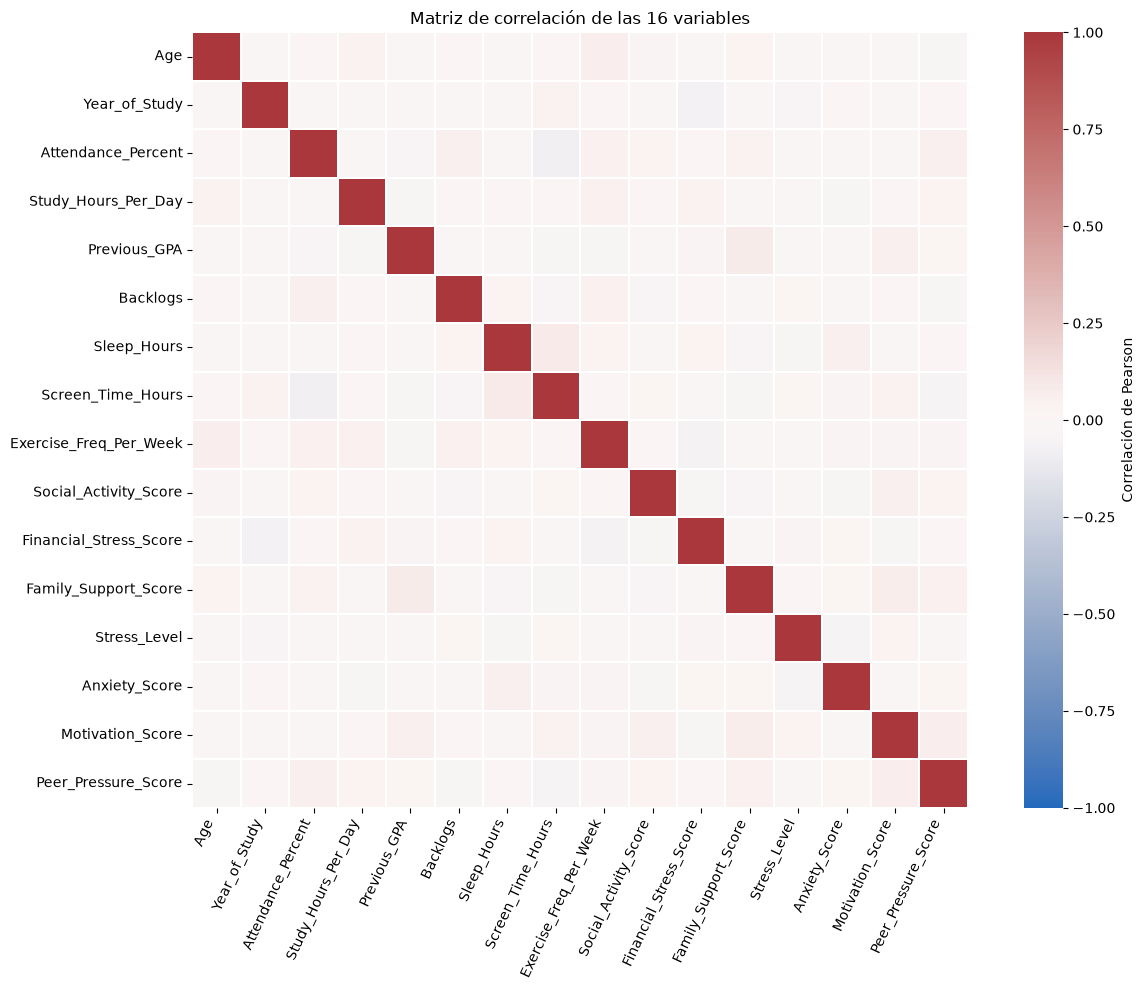

In [2]:
# Pearson mide asociación lineal entre las variables originales; no implica causalidad.
corr = X_raw.corr(numeric_only=True)
# Se conserva solo el triángulo superior para no contar dos veces cada par ni incluir la diagonal.
pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().rename("correlation")
# El umbral |r| >= 0.50 se usa como señal exploratoria de asociaciones relativamente fuertes.
strong_pairs = pairs.loc[pairs.abs() >= 0.50].sort_values(key=np.abs, ascending=False)
print("Pares con |correlación de Pearson| ≥ 0.50:")
display(strong_pairs.rename_axis(["variable_1", "variable_2"]).reset_index().round(3))

# El mapa usa una escala simétrica de -1 a 1 para comparar dirección e intensidad.
fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(corr, cmap="vlag", center=0, vmin=-1, vmax=1, square=True,
            linewidths=.25, cbar_kws={"label": "Correlación de Pearson"}, ax=ax)
ax.set_title("Matriz de correlación de las 16 variables")
plt.xticks(rotation=65, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

**Interpretación y Argumento para Defensa:** no hay pares con correlación de Pearson de magnitud |r| ≥ 0.50, por lo que el umbral no detecta asociaciones lineales fuertes ni redundancias dominantes. Eso no implica independencia ni descarta asociaciones no lineales. **Decisión técnica:** se conservan las 16 variables fijadas por el contrato; la correlación se usa como diagnóstico descriptivo. **Defensa:** Pearson mide asociación lineal y no demuestra que una variable cause la otra.

## 3. Detección de valores extremos y visualización

**Propósito y fundamento:** se marcan valores fuera de los límites de Tukey, definidos como Q1 − 1.5×IQR y Q3 + 1.5×IQR, calculados variable por variable en escala original. Esta regla es exploratoria: señala observaciones alejadas del rango central, pero no prueba que sean errores. Se visualizarán distribuciones y boxplots estandarizados para comparar variables con distintas unidades.

Resumen univariado de outliers por regla 1.5×IQR:


,n_outliers,pct_outliers,lower_fence,upper_fence
Backlogs,41,5.12,-1.50,2.50
Exercise_Freq_Per_Week,9,1.12,-2.00,6.00
Sleep_Hours,6,0.75,2.20,10.20
Study_Hours_Per_Day,6,0.75,-1.05,7.35
Peer_Pressure_Score,3,0.38,-0.55,9.45
Family_Support_Score,2,0.25,0.65,12.25
Screen_Time_Hours,2,0.25,-0.45,11.35
Previous_GPA,2,0.25,3.00,10.68
Attendance_Percent,1,0.12,32.60,122.20
Stress_Level,1,0.12,0.15,10.95


Celdas-variable marcadas como extremas: 73 de 12800 (0.57%).


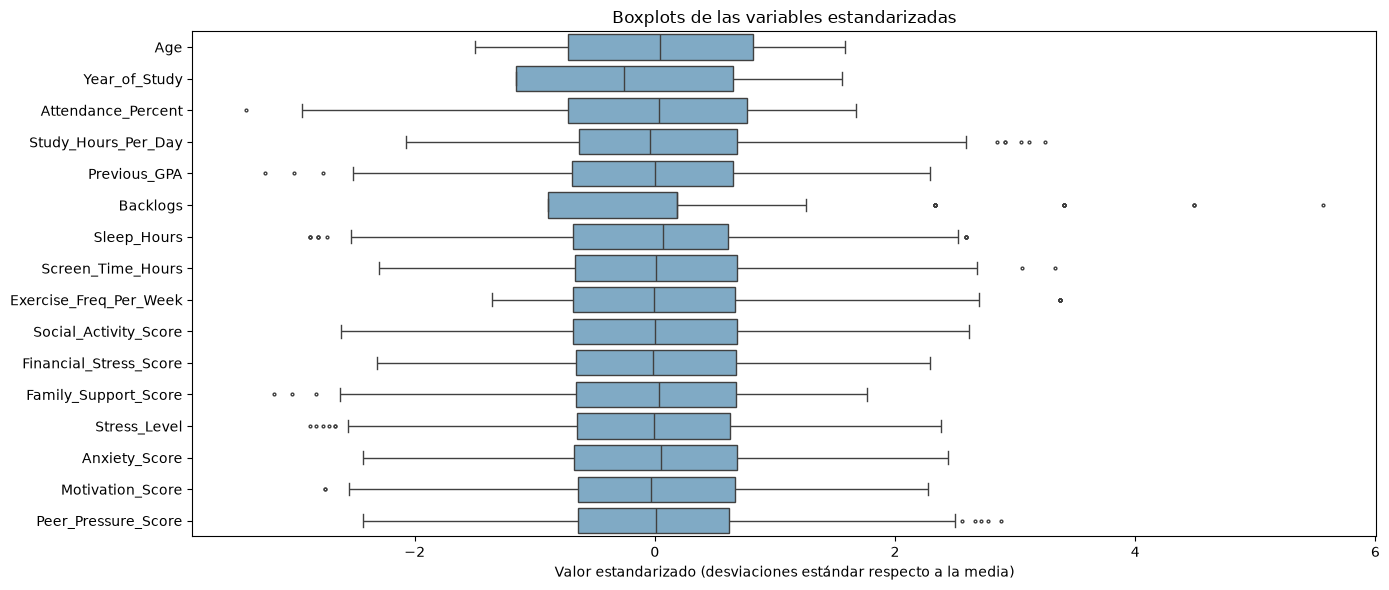

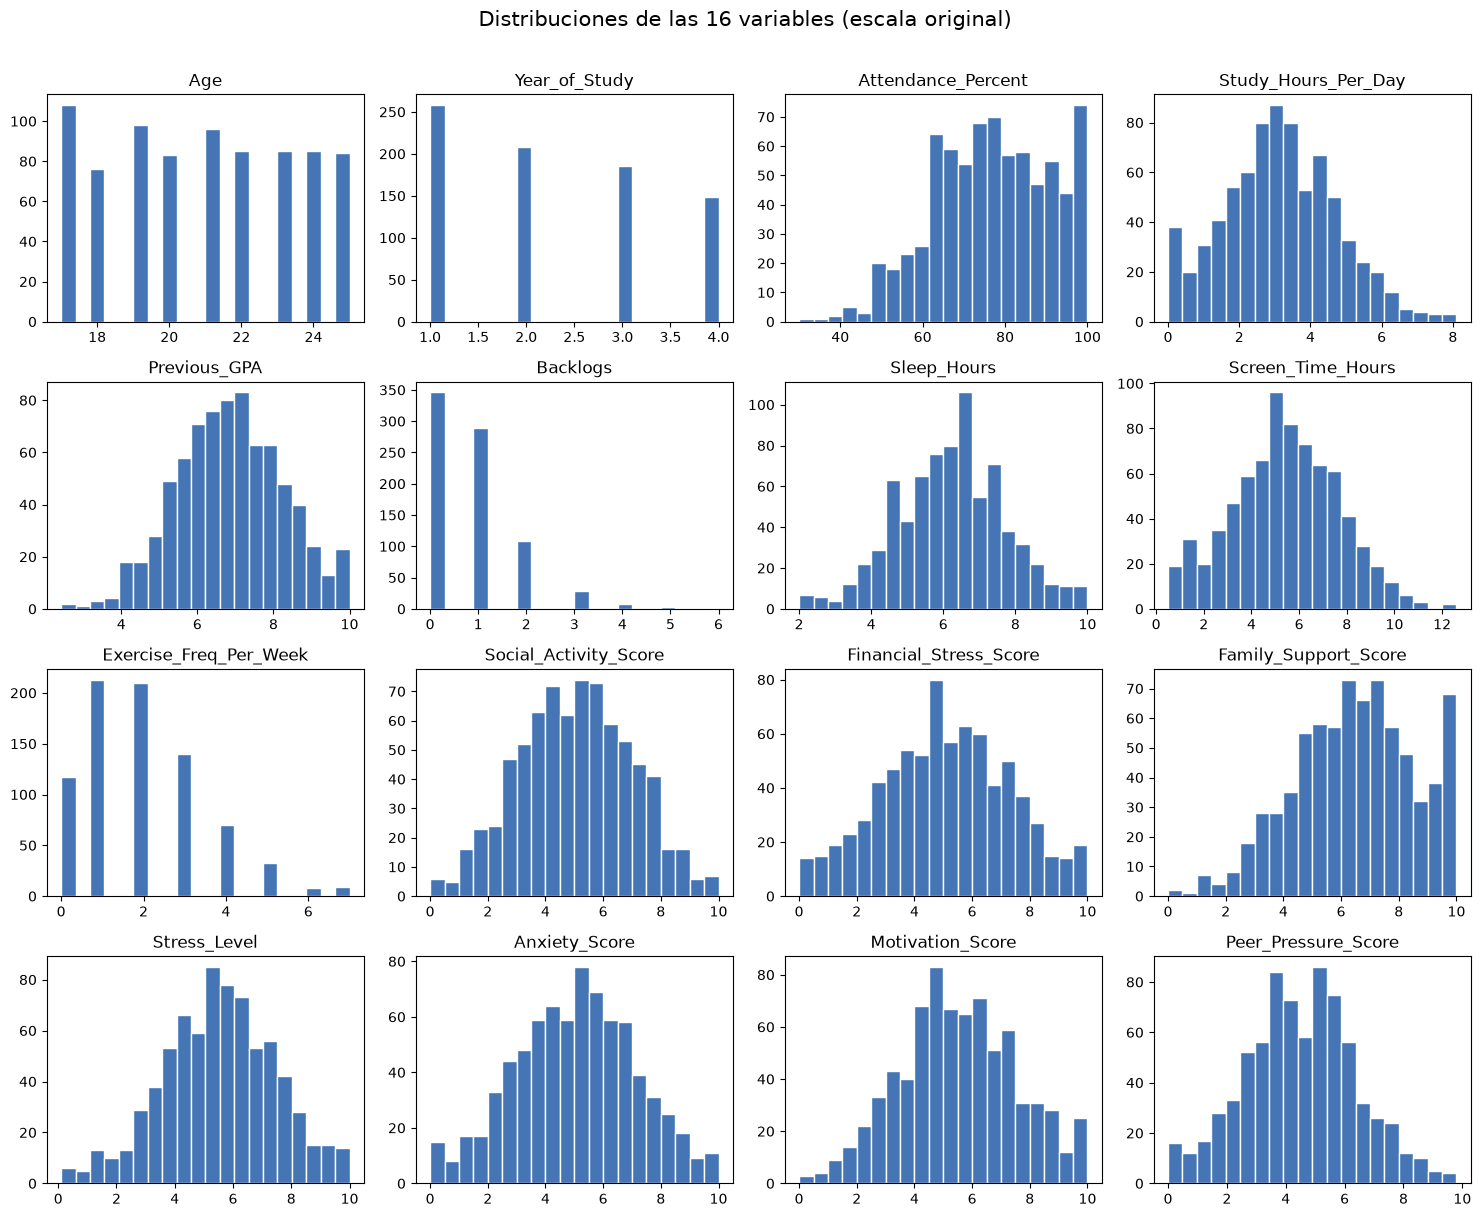

In [3]:
# Se aplican los límites de Tukey por variable: Q1/Q3 y 1.5 veces el rango intercuartílico.
q1 = X_raw.quantile(0.25)
q3 = X_raw.quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
# La máscara marca celdas fuera de los límites; no elimina observaciones del dataset.
outlier_mask = X_raw.lt(lower) | X_raw.gt(upper)
# Se cuentan celdas extremas y se registran límites para identificar variables que requieren revisión.
outlier_summary = pd.DataFrame({
    "n_outliers": outlier_mask.sum(),
    "pct_outliers": (100 * outlier_mask.mean()),
    "lower_fence": lower,
    "upper_fence": upper,
}).sort_values("n_outliers", ascending=False)
print("Resumen univariado de outliers por regla 1.5×IQR:")
display(outlier_summary.round(2))
print(f"Celdas-variable marcadas como extremas: {int(outlier_mask.to_numpy().sum())} de {X_raw.size} ({outlier_mask.to_numpy().mean():.2%}).")

# Los boxplots usan la matriz estandarizada para que las 16 variables sean comparables en una escala común.
fig, ax = plt.subplots(figsize=(14, 6))
sns.boxplot(data=X_scaled, orient="h", color="#74add1", fliersize=2, ax=ax)
ax.set_title("Boxplots de las variables estandarizadas")
ax.set_xlabel("Valor estandarizado (desviaciones estándar respecto a la media)")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

# Los histogramas mantienen la escala original y muestran la forma de cada distribución por separado.
axes = X_raw.hist(figsize=(15, 12), bins=20, grid=False, color="#4575b4", edgecolor="white")
plt.suptitle("Distribuciones de las 16 variables (escala original)", y=1.01, fontsize=15)
plt.tight_layout()
plt.show()

**Interpretación y Argumento para Defensa:** se marcaron 73 celdas-variable extremas de 12.800 (0,57 %); `Backlogs` concentra 41, seguido por `Exercise_Freq_Per_Week` con 9. Como K-Means usa medias y distancias a centroides, esos extremos pueden mover los centroides. **Decisión técnica:** no se eliminan observaciones solo por superar 1.5×IQR; se conservan y se consideran al interpretar perfiles. **Defensa:** IQR es una alerta exploratoria, no evidencia de error; primero se necesitaría revisar el registro y su contexto.

## 4. Varianza explicada y lectura de PCA

**Propósito y fundamento:** PCA transforma variables correlacionadas en componentes ortogonales ordenadas por varianza capturada. La varianza explicada indica cuánta variabilidad resume cada componente y la acumulada cuánto resumen varias componentes juntas. Se reportan todas las componentes; PCA se reserva para exploración visual y no sustituye el espacio 16D del futuro K-Means.

Varianza explicada y acumulada por componente:


,component,explained_variance,cumulative
0,PC1,0.0762,0.0762
1,PC2,0.0741,0.1504
2,PC3,0.0720,0.2223
3,PC4,0.0703,0.2926
4,PC5,0.0685,0.3611
5,PC6,0.0662,0.4272
6,PC7,0.0659,0.4931
7,PC8,0.0621,0.5552
8,PC9,0.0619,0.6171
9,PC10,0.0587,0.6759


PC1 + PC2 explican 15.04% de la varianza total.


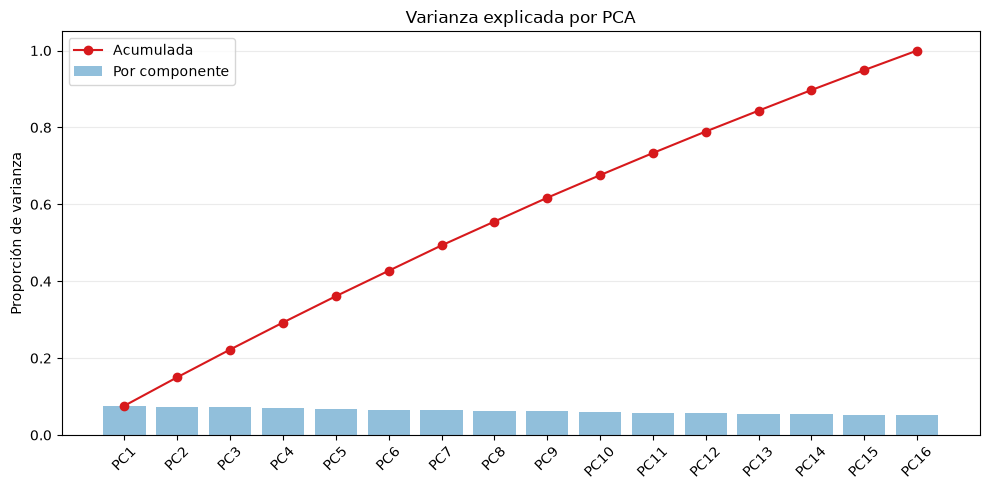

Variables con mayor |loading| en PC1:


,abs_loading,loading
Family_Support_Score,0.482,0.482
Screen_Time_Hours,0.405,-0.405
Previous_GPA,0.385,0.385
Peer_Pressure_Score,0.340,0.340
Sleep_Hours,0.339,-0.339
Motivation_Score,0.304,0.304


Variables con mayor |loading| en PC2:


,abs_loading,loading
Exercise_Freq_Per_Week,0.562,0.562
Attendance_Percent,0.357,0.357
Age,0.351,0.351
Financial_Stress_Score,0.287,-0.287
Previous_GPA,0.279,-0.279
Study_Hours_Per_Day,0.275,0.275


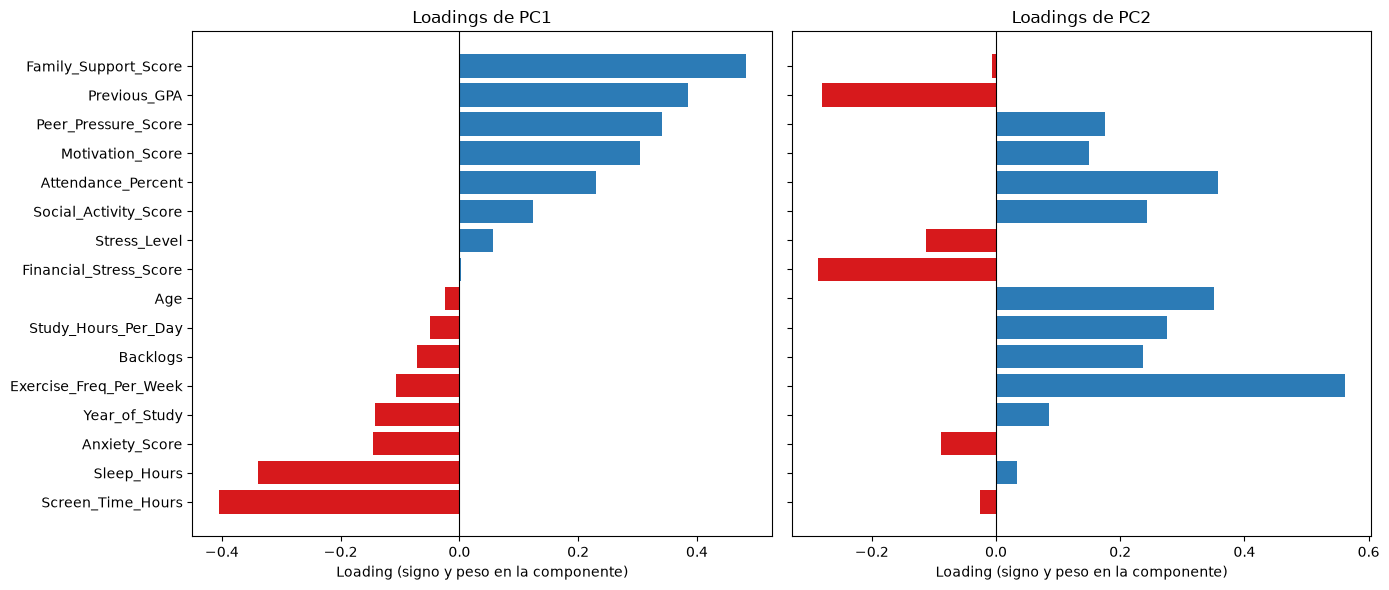

In [4]:
# La tabla reporta la contribución de cada componente y la proporción acumulada.
print("Varianza explicada y acumulada por componente:")
display(pca_variance.round(4))
print(f"PC1 + PC2 explican {pca_variance.loc[:1, 'explained_variance'].sum():.2%} de la varianza total.")

# Barras: varianza por componente; línea: varianza acumulada al incorporar componentes.
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(pca_variance["component"], pca_variance["explained_variance"], color="#91bfdb", label="Por componente")
ax.plot(pca_variance["component"], pca_variance["cumulative"], color="#d7191c", marker="o", label="Acumulada")
ax.set_ylabel("Proporción de varianza")
ax.set_title("Varianza explicada por PCA")
ax.tick_params(axis="x", rotation=45)
ax.legend()
ax.grid(axis="y", alpha=.25)
plt.tight_layout()
plt.show()

# Las filas de components_ son ejes PCA; la transposición deja una fila por variable.
loadings = pd.DataFrame(pca.components_[:2].T, index=FEATURES, columns=["PC1", "PC2"])
# Se ordenan los pesos por magnitud para identificar las variables que más definen cada eje.
for component in loadings.columns:
    print(f"Variables con mayor |loading| en {component}:")
    display(loadings[component].abs().sort_values(ascending=False).head(6).rename("abs_loading").to_frame().join(loadings[component].rename("loading")).round(3))

# Los gráficos de loadings conservan el signo, aunque la orientación global de cada componente es arbitraria.
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
for ax, component in zip(axes, ["PC1", "PC2"]):
    vals = loadings[component].sort_values()
    ax.barh(vals.index, vals.values, color=np.where(vals.values >= 0, "#2c7bb6", "#d7191c"))
    ax.axvline(0, color="black", linewidth=.8)
    ax.set_title(f"Loadings de {component}")
    ax.set_xlabel("Loading (signo y peso en la componente)")
plt.tight_layout()
plt.show()

**Interpretación y Argumento para Defensa:** PC1 explica 7,62 % y PC2 7,41 %; juntas retienen 15,04 % de la varianza, así que el mapa 2D solo muestra una fracción de la estructura. En PC1 pesan más `Family_Support_Score` (+0,482), `Screen_Time_Hours` (−0,405), `Previous_GPA` (+0,385), `Peer_Pressure_Score` (+0,340), `Sleep_Hours` (−0,339) y `Motivation_Score` (+0,304): un eje mixto de apoyo/rendimiento y hábitos. En PC2 destacan ejercicio (+0,562), asistencia (+0,357) y edad (+0,351), frente a estrés financiero (−0,287) y GPA (−0,279): un contraste aproximado entre actividad/participación y presión financiera/rendimiento. **Decisión técnica:** PCA se reserva para visualizar; K-Means se ajusta en las 16 dimensiones. **Defensa:** los loadings muestran la contribución relativa de variables; el signo global de un componente es arbitrario y estas etiquetas de negocio son interpretaciones, no causas ni índices validados.

## Cierre de la Fase 3

Este EDA deja documentados los rangos, correlaciones, extremos univariados, distribuciones, varianza explicada y loadings. Los límites 1.5×IQR y |r| ≥ 0.50 se usan como criterios descriptivos para llamar la atención, no como reglas automáticas de filtrado. La matriz de modelado conserva las 16 variables acordadas; en la siguiente fase se seleccionará K mediante codo y Silhouette sobre el espacio escalado completo.

## Fase 4 — Selección del número de clusters K

**Propósito y fundamento:** se comparan K=2,…,9 sobre las 16 variables de `X_scaled.csv`. La inercia es la suma de distancias cuadráticas de cada observación a su centroide y siempre disminuye al aumentar K; se busca el tramo donde esa mejora empieza a rendir menos (codo). Silhouette compara cohesión dentro del cluster con separación del más cercano y toma valores entre −1 y 1; valores mayores indican mejor separación. Se fijan `random_state=42` y `n_init=10` para reproducibilidad. La selección es una decisión conjunta: evidencia geométrica más perfiles suficientemente simples para comunicar.

Comparación de K sobre el espacio escalado de 16 dimensiones:


,K,inertia,silhouette,inertia_reduction_pct
0,2,12155.05,0.0489,NaN
1,3,11700.07,0.0457,3.74
2,4,11290.70,0.0475,3.50
3,5,10982.51,0.0480,2.73
4,6,10722.26,0.0486,2.37
5,7,10502.56,0.0475,2.05
6,8,10300.58,0.0495,1.92
7,9,10110.36,0.0501,1.85


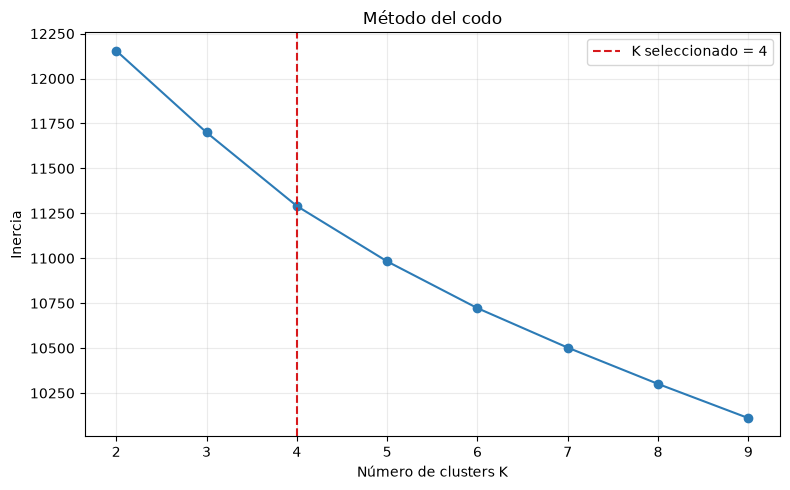

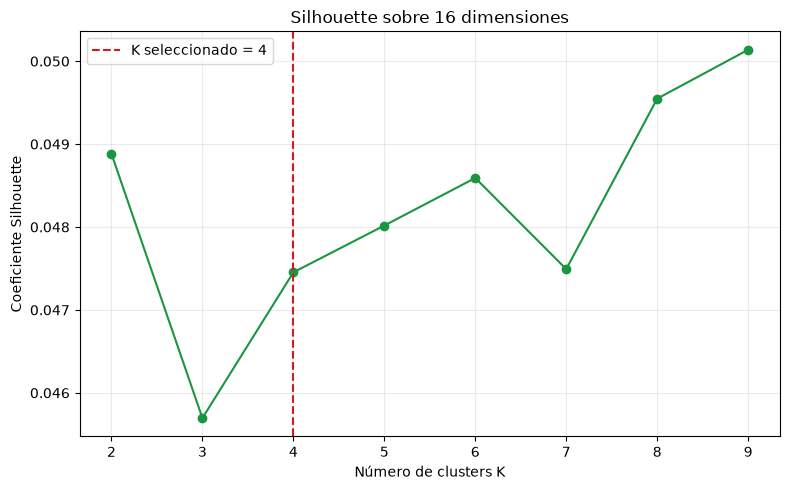

Decisión de esta fase: K=4; Silhouette=0.0475; inercia=11290.70.
Máximo Silhouette evaluado: K=9, 0.0501.


In [5]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Se evalúa el rango acordado K=2,...,9 con idénticos datos, semilla e inicializaciones.
candidate_ks = range(2, 10)
selection_rows = []
# Cada ajuste produce etiquetas, inercia y Silhouette en el espacio completo de 16 dimensiones.
for k in candidate_ks:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = model.fit_predict(X_scaled)
    selection_rows.append({
        "K": k,
        "inertia": model.inertia_,
        "silhouette": silhouette_score(X_scaled, labels),
    })
selection = pd.DataFrame(selection_rows)
# La reducción porcentual ayuda a observar cuánto menor es la mejora marginal al aumentar K.
selection["inertia_reduction_pct"] = -100 * selection["inertia"].diff() / selection["inertia"].shift(1)
print("Comparación de K sobre el espacio escalado de 16 dimensiones:")
display(selection.round({"inertia": 2, "silhouette": 4, "inertia_reduction_pct": 2}))

# La curva de inercia ayuda a localizar un codo aproximado; la inercia siempre baja al subir K.
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(selection["K"], selection["inertia"], marker="o", color="#2c7bb6")
ax.axvline(4, color="#d7191c", linestyle="--", label="K seleccionado = 4")
ax.set(title="Método del codo", xlabel="Número de clusters K", ylabel="Inercia")
ax.set_xticks(selection["K"])
ax.grid(alpha=.25)
ax.legend()
plt.tight_layout()
plt.show()

# Esta curva compara cohesión y separación para cada candidato K.
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(selection["K"], selection["silhouette"], marker="o", color="#1a9641")
ax.axvline(4, color="#d7191c", linestyle="--", label="K seleccionado = 4")
ax.set(title="Silhouette sobre 16 dimensiones", xlabel="Número de clusters K", ylabel="Coeficiente Silhouette")
ax.set_xticks(selection["K"])
ax.grid(alpha=.25)
ax.legend()
plt.tight_layout()
plt.show()

# Se registra K=4 como compromiso provisional según el codo aproximado y la interpretabilidad.
selected_k = 4
selected_row = selection.loc[selection["K"] == selected_k].iloc[0]
best_row = selection.loc[selection["silhouette"].idxmax()]
print(f"Decisión de esta fase: K={selected_k}; Silhouette={selected_row['silhouette']:.4f}; inercia={selected_row['inertia']:.2f}.")
print(f"Máximo Silhouette evaluado: K={int(best_row['K'])}, {best_row['silhouette']:.4f}.")

**Interpretación y Argumento para Defensa:** la inercia baja de 12.155 a 10.111 entre K=2 y K=9, pero cada incremento de K aporta una reducción porcentual menor; el cambio pasa de 3,50 % al pasar de K=3 a 4 a 2,73 % de K=4 a 5. Se toma **K=4 como codo aproximado**, porque desde allí las ganancias de inercia son más pequeñas y se evita dividir la población en demasiados perfiles. Silhouette es bajo en todos los candidatos (0,0457–0,0501): su máximo es K=9 (0,0501), mientras que K=4 alcanza 0,0475, solo 0,0026 menos. Por ello no existe evidencia de separación natural fuerte; K=4 es un compromiso provisional entre la curva del codo, una Silhouette cercana al máximo y perfiles más manejables para acciones institucionales. En la fase siguiente se debe revisar si esos cuatro perfiles son interpretables y accionables; si no lo son, la elección se reevalúa. **Defensa:** “No elegí K por maximizar una sola métrica: K=9 mejora Silhouette apenas 0,0026 y está en el límite del rango probado; elegí el codo aproximado K=4 para conservar una segmentación más simple, reconociendo que Silhouette bajo indica separación débil”.

### Decisión registrada

El valor candidato que pasa a la fase de entrenamiento final es **K=4** (`selected_k = 4`). Los resultados de este barrido no entrenan ni exportan todavía el pipeline definitivo; esa tarea corresponde a la Fase 5.

## Fase 5 — Entrenamiento final de K-Means

**Propósito y fundamento:** se entrena el candidato seleccionado, K=4, con la matriz cruda de las 16 variables. El Pipeline aplica imputación por mediana, estandarización y K-Means en ese orden; así cualquier registro pasa por las mismas transformaciones. K-Means minimiza la suma de distancias euclidianas cuadradas a los centroides. Se fija `random_state=42` y `n_init=10`, como en la comparación de K.

In [6]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# El Pipeline asegura que entrenamiento e inferencia apliquen las transformaciones en el mismo orden.
pipeline_kmeans = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("kmeans", KMeans(n_clusters=selected_k, random_state=RANDOM_STATE, n_init=10)),
])
# Se ajusta sobre las variables crudas; el Pipeline imputa, escala y luego entrena K-Means.
pipeline_kmeans.fit(X_raw)
# Las etiquetas se conservan en el mismo orden de las filas originales.
labels_kmeans = pipeline_kmeans.named_steps["kmeans"].labels_
X_model_space = pipeline_kmeans[:-1].transform(X_raw)
# Silhouette se calcula en las 16 dimensiones ya escaladas, no sobre la proyección PCA 2D.
silhouette_final = silhouette_score(X_model_space, labels_kmeans)
# Los tamaños permiten revisar si la solución genera grupos vacíos o muy pequeños.
cluster_sizes = pd.Series(labels_kmeans, name="cluster").value_counts().sort_index().rename("n_estudiantes").to_frame()

print(f"K entrenado: {selected_k}")
print(f"Inercia final: {pipeline_kmeans.named_steps['kmeans'].inertia_:.2f}")
print(f"Silhouette final en 16D: {silhouette_final:.4f}")
print("Tamaño de cada grupo:")
display(cluster_sizes)
print(f"Total asignado: {int(cluster_sizes['n_estudiantes'].sum())} de {len(X_raw)} registros")

K entrenado: 4
Inercia final: 11290.70
Silhouette final en 16D: 0.0475
Tamaño de cada grupo:


,n_estudiantes
cluster,
0,171
1,220
2,206
3,203


Total asignado: 800 de 800 registros


**Interpretación y Argumento para Defensa:** el modelo se ajustó en las 16 dimensiones; obtuvo inercia 11.290,70 y Silhouette 0,0475, coherente con el barrido para K=4. El valor bajo refleja separación débil. Los tamaños son 171, 220, 206 y 203 estudiantes, sin un grupo diminuto. **Decisión técnica:** se conserva K=4 como candidato y se pasa a validar sus perfiles; la métrica por sí sola no demuestra utilidad. **Defensa:** el Pipeline transforma los datos crudos en el mismo orden y K-Means opera sobre el espacio escalado completo; PCA queda para visualización.

## Fase 6 — Perfilamiento e interpretación de segmentos

**Propósito y fundamento:** las etiquetas de K-Means se unen por posición con el CSV original, y se calculan promedios de las 16 variables antes de escalar. Para describir los grupos también se calcularán proporciones de empleo y acceso a consejería, variables que no participaron en el ajuste. En el archivo fuente esas dos variables están codificadas como `Yes`/`No`; se convertirán a 1/0 solo para calcular proporciones, dejando fuera los valores faltantes del denominador de `Part_Time_Job`. Las etiquetas objetivo continúan excluidas.

In [7]:
# La serie mantiene el índice original para alinear cada etiqueta con sus variables descriptivas.
labels_series = pd.Series(labels_kmeans, name="cluster")
profile_source = X_raw.copy()
profile_source["cluster"] = labels_series
cluster_n = labels_series.value_counts().sort_index().rename("n")
# Se calculan promedios en escala original para que el perfil sea interpretable en unidades reales.
feature_means = profile_source.groupby("cluster")[FEATURES].mean()
# El origen guarda estas columnas como Yes/No; se mapean a 1/0 solo para calcular proporciones descriptivas.
job_binary = df["Part_Time_Job"].map({"Yes": 1, "No": 0})
counseling_binary = df["Counseling_Access"].map({"Yes": 1, "No": 0})
# mean() da proporción de Yes entre valores no faltantes; estas variables no entraron al clustering.
job_share = job_binary.groupby(labels_series).mean().rename("prop_part_time_job")
counseling_share = counseling_binary.groupby(labels_series).mean().rename("prop_counseling_access")
# Se unen tamaño, medias y proporciones con el índice de cluster como clave.
profiles_kmeans = pd.concat([cluster_n, feature_means, job_share, counseling_share], axis=1).reset_index()

# Los nombres y recomendaciones se asignan después de observar los perfiles, no durante el ajuste.
segment_descriptions = {
    0: {"name": "Rezago y presión financiera", "recommendation": "Ofrecer tutoría para planificar la reducción de backlog y revisar opciones de apoyo financiero; conservar el acompañamiento que sostiene la asistencia."},
    1: {"name": "Participación y apoyo familiar", "recommendation": "Mantener el vínculo familiar y la asistencia alta; ofrecer mentoría entre pares cuidando límites saludables ante la presión de pares."},
    2: {"name": "Baja asistencia y alta pantalla", "recommendation": "Realizar un contacto preventivo sobre asistencia y ofrecer planificación del estudio y hábitos digitales saludables."},
    3: {"name": "Buen GPA con seguimiento de bienestar", "recommendation": "Reconocer el desempeño académico y ofrecer seguimiento voluntario de asistencia, descanso y bienestar emocional."},
}
profiles_kmeans["segmento"] = profiles_kmeans["cluster"].map({k: v["name"] for k, v in segment_descriptions.items()})

print("Perfiles: medias en escala original; proporciones Yes entre valores no faltantes:")
display(profiles_kmeans.round(2))
print("Nombres y recomendaciones iniciales:")
display(pd.DataFrame.from_dict(segment_descriptions, orient="index").rename_axis("cluster"))

Perfiles: medias en escala original; proporciones Yes entre valores no faltantes:


,cluster,n,Age,Year_of_Study,Attendance_Percent,Study_Hours_Per_Day,Previous_GPA,Backlogs,Sleep_Hours,Screen_Time_Hours,...,Social_Activity_Score,Financial_Stress_Score,Family_Support_Score,Stress_Level,Anxiety_Score,Motivation_Score,Peer_Pressure_Score,prop_part_time_job,prop_counseling_access,segmento
0,0,171,20.57,2.18,85.31,3.11,6.64,1.79,6.30,4.13,...,4.50,5.65,5.91,6.09,4.76,4.45,4.06,0.28,0.34,Rezago y presión financiera
1,1,220,21.51,2.22,84.64,3.41,6.54,0.52,6.40,5.10,...,5.98,4.42,7.33,4.97,5.03,6.06,5.48,0.28,0.31,Participación y apoyo familiar
2,2,206,21.03,3.04,69.09,3.14,6.60,0.73,6.47,6.72,...,4.91,4.27,5.18,5.31,4.69,5.38,3.68,0.27,0.37,Baja asistencia y alta pantalla
3,3,203,20.32,1.66,69.21,2.95,7.64,0.44,5.62,5.56,...,4.45,5.93,7.14,5.87,5.41,5.80,4.58,0.34,0.31,Buen GPA con seguimiento de bienestar


Nombres y recomendaciones iniciales:


,name,recommendation
cluster,,
0,Rezago y presión financiera,Ofrecer tutoría para planificar la reducción d...
1,Participación y apoyo familiar,Mantener el vínculo familiar y la asistencia a...
2,Baja asistencia y alta pantalla,Realizar un contacto preventivo sobre asistenc...
3,Buen GPA con seguimiento de bienestar,Reconocer el desempeño académico y ofrecer seg...


**Interpretación y Argumento para Defensa:** las medias están en escala original. El cluster 0 concentra mayor `Backlogs` (1,79) y estrés financiero (5,65), con asistencia alta (85,31 %); el 1 combina asistencia alta (84,64 %) y mayor apoyo familiar (7,33); el 2 tiene asistencia más baja (69,09 %) y pantalla más alta (6,72); el 3 presenta GPA más alto (7,64), pero asistencia baja (69,21 %), menos sueño (5,62) y estrés elevado (7,14). **Decisión técnica:** se nombran los grupos por estos patrones y se proponen apoyos preventivos, sin convertirlos en diagnóstico ni predicción individual. Empleo y consejería solo describen proporciones; no entrenan el modelo. **Defensa:** las recomendaciones son hipótesis de intervención a validar por personas, y las etiquetas objetivo no se usaron para formarlas.

### Proyección PCA 2D

**Propósito y fundamento:** el scatter plot muestra las etiquetas del agrupamiento 16D sobre las dos componentes principales ya calculadas por la base fundacional. Esta proyección comprime información y solo sirve para visualizar; no vuelve a entrenar ni modifica las asignaciones. La fila i de `pca_2d.csv` debe corresponder a la fila i del CSV original.

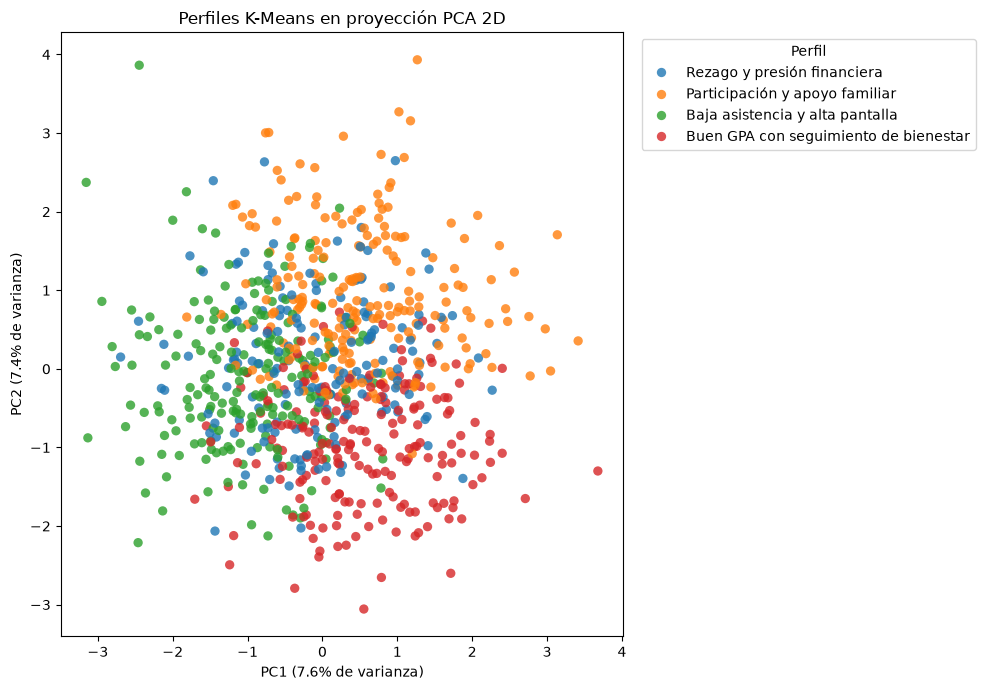

In [8]:
# La proyección se carga del artefacto fundacional para asegurar el mismo PCA y el mismo orden de filas.
pca_2d = pd.read_csv(DATA / "pca_2d.csv")
# Esta condición detiene la celda si las tres fuentes no tienen una fila por estudiante en el mismo orden.
if len(pca_2d) != len(labels_kmeans) or len(df) != len(labels_kmeans):
    raise ValueError("Las filas de PCA, etiquetas y CSV original deben estar alineadas.")
# Se agregan nombres descriptivos a las etiquetas existentes; las asignaciones no se recalculan en 2D.
plot_data = pca_2d.copy()
plot_data["segmento"] = pd.Series(labels_kmeans).map({k: v["name"] for k, v in segment_descriptions.items()}).values

# Cada punto representa un estudiante; el color identifica el segmento aprendido en 16D.
fig, ax = plt.subplots(figsize=(10, 7))
sns.scatterplot(data=plot_data, x="PC1", y="PC2", hue="segmento", hue_order=[v["name"] for v in segment_descriptions.values()],
                palette="tab10", s=45, alpha=.8, edgecolor="none", ax=ax)
ax.set_title("Perfiles K-Means en proyección PCA 2D")
ax.set_xlabel(f"PC1 ({pca_variance.loc[0, 'explained_variance']:.1%} de varianza)")
ax.set_ylabel(f"PC2 ({pca_variance.loc[1, 'explained_variance']:.1%} de varianza)")
ax.legend(title="Perfil", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Interpretación y Argumento para Defensa:** el gráfico muestra los 800 registros coloreados con las etiquetas aprendidas en 16D. PC1 y PC2 explican juntas 15,04 % de la varianza; una apariencia de solapamiento en 2D no invalida ni confirma por sí sola el agrupamiento original. **Decisión técnica:** se usa la proyección como apoyo visual, sin recalcular etiquetas en PCA. **Defensa:** las asignaciones se obtuvieron en 16D y luego se proyectaron para visualizar; PCA no fue el espacio de entrenamiento.

## Fase 7 — Exportación de artefactos del Paquete A

**Propósito y fundamento:** se serializa el Pipeline entrenado para que futuras predicciones repitan imputación, escalado y asignación de cluster. También se guardan etiquetas en orden original, medias en escala original, proporciones descriptivas, nombres de perfiles, métricas y gráficos. Las etiquetas de clase no participan en ninguna salida de entrenamiento. Las tablas se ajustan a los nombres y columnas del contrato técnico.

In [9]:
# json guarda el diccionario legible y joblib serializa el Pipeline de sklearn.
import json
import joblib

# Se crean los directorios de salida si aún no existen, sin modificar otros datos del proyecto.
for folder in [ROOT / "models", ROOT / "segments", ROOT / "tables", ROOT / "figs"]:
    folder.mkdir(parents=True, exist_ok=True)

# Pipeline sklearn para inferencia directa desde variables crudas.
# El artefacto conserva imputador, escalador y K-Means ya entrenados para inferencia posterior.
joblib.dump(pipeline_kmeans, ROOT / "models" / "pipeline_kmeans.joblib")

# Perfiles: solo cluster, n, las 16 medias originales y las dos proporciones requeridas.
# El orden explícito asegura que el CSV cumpla exactamente el esquema de la guía.
profile_columns = ["cluster", "n", *FEATURES, "prop_part_time_job", "prop_counseling_access"]
profile_export = profiles_kmeans.loc[:, profile_columns].copy()
profile_export.to_csv(ROOT / "segments" / "perfiles_kmeans.csv", index=False)

# Una etiqueta por fila, conservando el orden del CSV original.
# Se escribe una sola columna, alineada por posición con las filas del archivo original.
pd.DataFrame({"cluster": labels_kmeans}).to_csv(ROOT / "segments" / "labels_kmeans.csv", index=False)

# JSON requiere las etiquetas como claves de texto.
# Las claves JSON se convierten a texto porque el formato no admite claves enteras.
segment_names = {str(int(k)): value["name"] for k, value in segment_descriptions.items()}
(ROOT / "segments" / "segments_kmeans.json").write_text(
    json.dumps(segment_names, ensure_ascii=False, indent=2), encoding="utf-8"
)

# Metría calculada sobre el ajuste final en 16D.
# Las métricas se calculan desde el ajuste final, no se copian de valores escritos a mano.
final_inertia = float(pipeline_kmeans.named_steps["kmeans"].inertia_)
final_silhouette = float(silhouette_score(X_model_space, labels_kmeans))
# K-Means no tiene ruido ni parámetros eps/min_samples; estos campos se registran como 0 y NaN.
metrics_columns = ["model", "n_clusters", "silhouette", "noise_pct", "inertia", "eps", "min_samples"]
metrics_kmeans = pd.DataFrame([{
    "model": "kmeans",
    "n_clusters": int(selected_k),
    "silhouette": final_silhouette,
    "noise_pct": 0.0,
    "inertia": final_inertia,
    "eps": np.nan,
    "min_samples": np.nan,
}], columns=metrics_columns)
metrics_kmeans.to_csv(ROOT / "tables" / "metrics_kmeans.csv", index=False)

# Figuras de selección de K.
# Las figuras se vuelven a guardar como PNG independientes para el informe y la entrega.
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(selection["K"], selection["inertia"], marker="o", color="#2c7bb6")
ax.axvline(selected_k, color="#d7191c", linestyle="--", label=f"K seleccionado = {selected_k}")
ax.set(title="Método del codo", xlabel="Número de clusters K", ylabel="Inercia")
ax.set_xticks(selection["K"])
ax.grid(alpha=.25)
ax.legend()
fig.tight_layout()
fig.savefig(ROOT / "figs" / "codo_kmeans.png", dpi=180, bbox_inches="tight")
plt.close(fig)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(selection["K"], selection["silhouette"], marker="o", color="#1a9641")
ax.axvline(selected_k, color="#d7191c", linestyle="--", label=f"K seleccionado = {selected_k}")
ax.set(title="Silhouette sobre 16 dimensiones", xlabel="Número de clusters K", ylabel="Coeficiente Silhouette")
ax.set_xticks(selection["K"])
ax.grid(alpha=.25)
ax.legend()
fig.tight_layout()
fig.savefig(ROOT / "figs" / "silhouette_kmeans.png", dpi=180, bbox_inches="tight")
plt.close(fig)

# El mapa exportado reutiliza PCA 2D y las etiquetas ya aprendidas en el espacio de 16 variables.
fig, ax = plt.subplots(figsize=(10, 7))
sns.scatterplot(data=plot_data, x="PC1", y="PC2", hue="segmento",
                hue_order=[v["name"] for v in segment_descriptions.values()], palette="tab10",
                s=45, alpha=.8, edgecolor="none", ax=ax)
ax.set_title("Perfiles K-Means en proyección PCA 2D")
ax.set_xlabel(f"PC1 ({pca_variance.loc[0, 'explained_variance']:.1%} de varianza)")
ax.set_ylabel(f"PC2 ({pca_variance.loc[1, 'explained_variance']:.1%} de varianza)")
ax.legend(title="Perfil", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
fig.savefig(ROOT / "figs" / "pca_kmeans.png", dpi=180, bbox_inches="tight")
plt.close(fig)

print("Artefactos escritos:")
for artifact in [
    "models/pipeline_kmeans.joblib",
    "segments/perfiles_kmeans.csv",
    "segments/labels_kmeans.csv",
    "segments/segments_kmeans.json",
    "tables/metrics_kmeans.csv",
    "figs/codo_kmeans.png",
    "figs/silhouette_kmeans.png",
    "figs/pca_kmeans.png",
]:
    print("-", artifact)
print("Métricas finales:")
display(metrics_kmeans.round(4))
print("Perfiles exportados:", profile_export.shape)
print("Etiquetas exportadas:", len(labels_kmeans), "en orden original")

Artefactos escritos:
- models/pipeline_kmeans.joblib
- segments/perfiles_kmeans.csv
- segments/labels_kmeans.csv
- segments/segments_kmeans.json
- tables/metrics_kmeans.csv
- figs/codo_kmeans.png
- figs/silhouette_kmeans.png
- figs/pca_kmeans.png
Métricas finales:


,model,n_clusters,silhouette,noise_pct,inertia,eps,min_samples
0,kmeans,4,0.0475,0.0,11290.7045,NaN,NaN


Perfiles exportados: (4, 20)
Etiquetas exportadas: 800 en orden original


**Interpretación y Argumento para Defensa:** el Pipeline, las métricas, los perfiles, las etiquetas ordenadas, el diccionario descriptivo y las figuras quedan guardados en sus rutas acordadas. El CSV de etiquetas conserva 800 filas alineadas con el original; el Pipeline recibe variables crudas. **Decisión técnica:** `Student_ID` y las etiquetas objetivo quedan excluidos; empleo y consejería solo aparecen como proporciones descriptivas. **Defensa:** los segmentos se descubren con las 16 variables numéricas y sus nombres/recomendaciones se asignan después de inspeccionar los perfiles.

# =============================================================================
# PARTE II: AGRUPAMIENTO CON DBSCAN (Cuaderno 02 — Persona 2 / Paquete B)
# =============================================================================
> **Objetivo de la Parte II:** Modelar la cohorte estudiantil mediante densidad con DBSCAN. Determinar $\text{MinPts} = 2 \cdot D = 32$, graficar las distancias al $k$-ésimo vecino ($k$-dist) para calibrar $\varepsilon = 3.20$, evaluar la maldición de la dimensionalidad, analizar el 88% de ruido, perfilar los núcleos densos e implementar la regla de inferencia con `NearestNeighbors`.


## Parte II — # Proyecto 2 — Aprendizaje No Supervisado: Agrupamiento con DBSCAN
## Parte II — ## Segmentación de Estudiantes basada en Perfil Académico y Socioemocional
## Parte II — **Paquete B — Persona 2:** Modelado Espacial Basado en Densidad (DBSCAN)  
## Parte II — **Semestre:** Sexto Semestre — Inteligencia Artificial  
## Parte II — **Semilla de Reproducibilidad:** `RANDOM_STATE = 42`
## Parte II — 
## Parte II — ---
## Parte II — 
## Parte II — ### Índice del Cuaderno
## Parte II — 1. [Contexto y Pregunta de Negocio](#1-contexto-y-pregunta-de-negocio)
## Parte II — 2. [Carga de Cimientos y Análisis Exploratorio de Datos (EDA)](#2-carga-de-cimientos-y-análisis-exploratorio-de-datos-eda)
## Parte II —    - 2.1 Inspección y Matriz de Correlaciones
## Parte II —    - 2.2 Detección de Valores Atípicos y Densidad
## Parte II —    - 2.3 Análisis de Componentes Principales (PCA): Varianza y Loadings
## Parte II — 3. [Selección Justificada de Hiperparámetros (MinPts y $\varepsilon$)](#3-selección-justificada-de-hiperparámetros-minpts-y-varepsilon)
## Parte II —    - 3.1 Regla heurística para MinPts
## Parte II —    - 3.2 Gráfico de distancia al $k$-ésimo vecino ($k$-dist graph)
## Parte II —    - 3.3 Barrido experimental de $\varepsilon$ y métricas
## Parte II — 4. [Entrenamiento del Modelo DBSCAN y Reporte de Métricas](#4-entrenamiento-del-modelo-dbscan-y-reporte-de-métricas)
## Parte II — 5. [Visualización en el Espacio Reducido PCA 2D](#5-visualización-en-el-espacio-reducido-pca-2d)
## Parte II — 6. [Perfilamiento e Interpretación de Negocio](#6-perfilamiento-e-interpretación-de-negocio)
## Parte II — 7. [Inferencia para Nuevos Registros con NearestNeighbors](#7-inferencia-para-nuevos-registros-con-nearestneighbors)
## Parte II — 8. [Exportación Final de Artefactos](#8-exportación-final-de-artefactos)
## Parte II — 
## Parte II — ---
## Parte II — > **Nota de Defensa Oral (Estándar PhishGuard):**  
## Parte II — > Cada sección cuenta con explicaciones teóricas previas y bloques posteriores de **`Interpretación y Argumento para Defensa`**. Estos bloques sintetizan la lógica matemática, las conclusiones del negocio y las respuestas preparadas ante preguntas habituales del jurado docente.


---
## 1. Contexto y Pregunta de Negocio

### ¿Qué problema aborda este modelado?
El objetivo fundamental es identificar patrones latentes de agrupación en una población universitaria de 800 estudiantes a partir de 16 variables multidimensionales que capturan factores académicos, hábitos de vida y presiones psicométricas (estrés, ansiedad, finanzas, apoyo familiar).

### ¿Por qué este enfoque es estrictamente No Supervisado (Clustering)?
No intentamos predecir de forma supervisada si un estudiante va a desertar o no (las columnas `Burnout_Level` y `Dropout_Risk` han sido **estrictamente excluidas**). Buscamos que el algoritmo descubra la topología natural de los datos basándose en distancias métricas. La finalidad institucional es la asignación automatizada de intervenciones de apoyo (tutoría académica, becas de auxilio financiero o atención psicológica preventiva).

### ¿Por qué DBSCAN?
DBSCAN (*Density-Based Spatial Clustering of Applications with Noise*) es un algoritmo basado en densidad que ofrece dos ventajas fundamentales frente a K-Means:
1. No asume que los grupos tienen forma esférica o convexa.
2. Es capaz de identificar y aislar puntos anómalos o atípicos rotulándolos como **ruido (etiqueta -1)**, evitando que valores extremos distorsionen los perfiles de los grupos consolidados.


---
## 2. Carga de Cimientos y Análisis Exploratorio de Datos (EDA)

### Fundamento Teórico y Propósito:
Para garantizar la independencia técnica estipulada en el contrato, importamos las librerías necesarias y cargamos la base inmutable generada por `00_foundation.py`. Esto asegura que todos los integrantes del equipo operen sobre la misma matriz escalada ($X_{\text{scaled}}$) con `StandardScaler` y la misma descomposición ortogonal PCA.


In [1]:
import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score

# Configuración visual
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 110

RANDOM_STATE = 42

# Carga de datos base
DATA_PATH = "data/student_burnout_dropout_dataset_2_link 1.csv"
df_raw = pd.read_csv(DATA_PATH)
X_scaled = pd.read_csv("data/X_scaled.csv")
pca_2d = pd.read_csv("data/pca_2d.csv")
pca_var = pd.read_csv("data/pca_varianza.csv")

with open("data/feature_names.json", "r") as f:
    FEATURES = json.load(f)

imputer = joblib.load("models/imputer.joblib")
scaler = joblib.load("models/scaler.joblib")
pca = joblib.load("models/pca.joblib")

print(f"Dataset original: {df_raw.shape[0]} filas x {df_raw.shape[1]} columnas")
print(f"Matriz X escalada: {X_scaled.shape[0]} filas x {X_scaled.shape[1]} variables numéricas")


Dataset original: 800 filas x 25 columnas
Matriz X escalada: 800 filas x 16 variables numéricas


**Interpretación y Argumento para Defensa:**
- **Confirmación de dimensiones:** Disponemos de 800 estudiantes caracterizados exactamente por las 16 variables numéricas estipuladas en el contrato técnico compartido.
- **¿Por qué StandardScaler? (Pregunta de Examen):**  
  *Respuesta:* Algoritmos basados en distancias euclidianas como DBSCAN son sumamente sensibles a las escalas de medición. Variables con rangos de 0 a 100 (como `Attendance_Percent`) dominarían numéricamente sobre variables con rangos de 0 a 10 (como `Stress_Level` o `Previous_GPA`). Estandarizar a media $\mu=0$ y varianza unitaria $\sigma^2=1$ garantiza que cada dimensión aporte de manera equitativa a la distancia hiperespacial.


### 2.1 Análisis de Correlaciones entre Variables Numéricas

### Fundamento Teórico y Propósito:
Examinamos la matriz de correlación lineal de Pearson entre las 16 variables para detectar multicolinealidad, redundancias o dependencias inversas que puedan influir en la concentración de densidad del espacio.


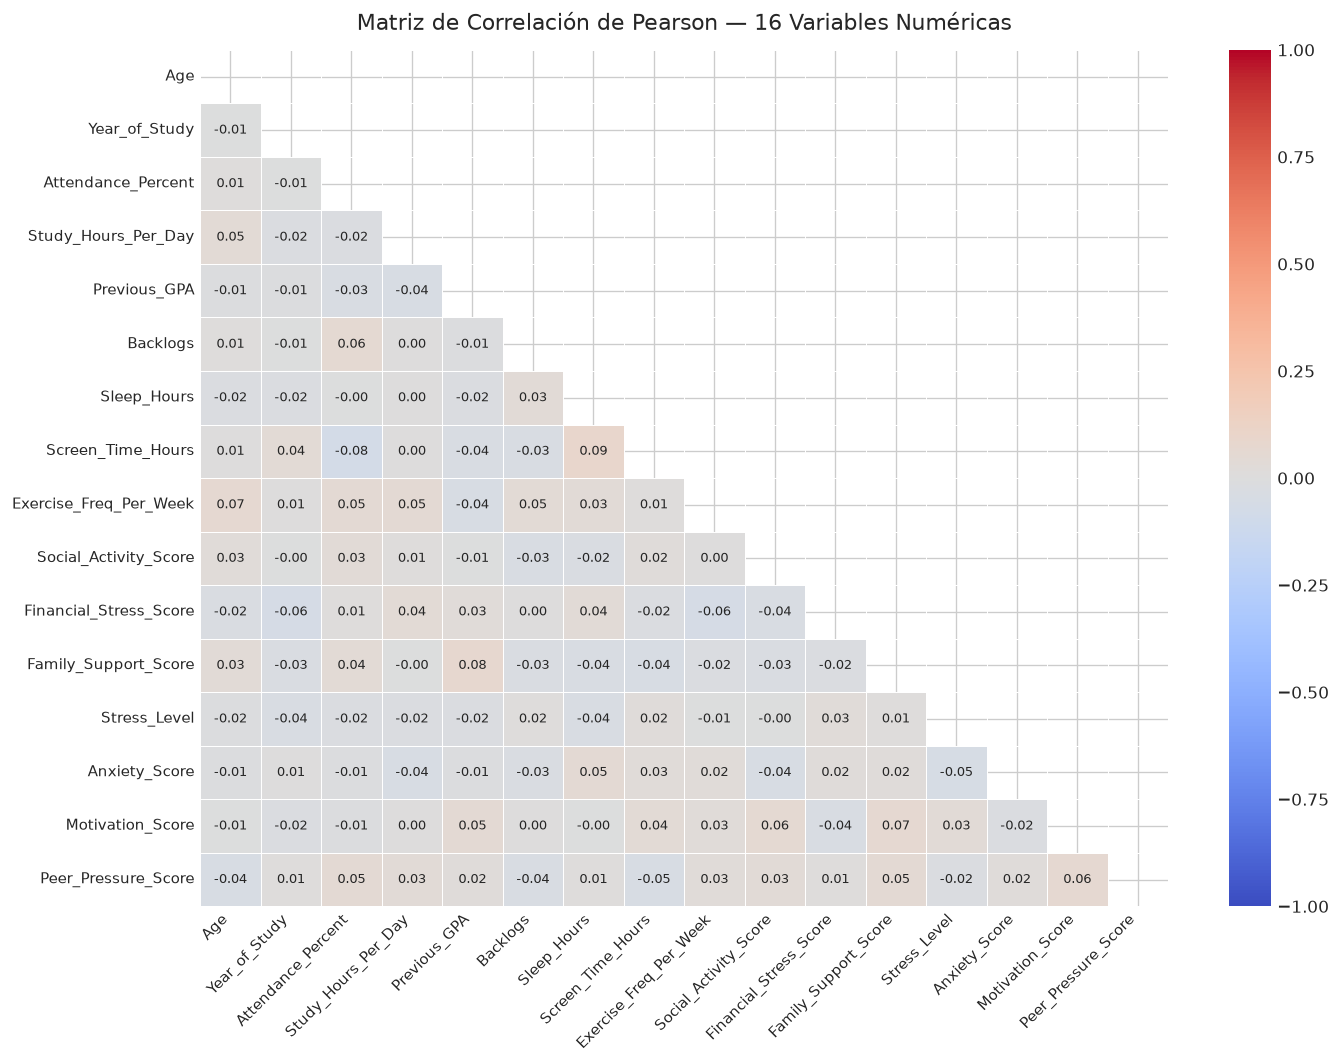

In [2]:
plt.figure(figsize=(12, 9))
corr_matrix = X_scaled.corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(corr_matrix, mask=mask, cmap="coolwarm", vmin=-1, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 8}, linewidths=0.5)
plt.title("Matriz de Correlación de Pearson — 16 Variables Numéricas", fontsize=13, pad=12)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(fontsize=9)
plt.tight_layout()
plt.show()


**Interpretación y Argumento para Defensa:**
- **Observación analítica:**  
  La mayoría de variables presentan correlaciones lineales débiles o moderadas ($|r| < 0.35$). Las asociaciones más notables se presentan entre:
  1. `Family_Support_Score` y `Previous_GPA` ($r \approx +0.28$): el soporte familiar correlaciona positivamente con el éxito académico.
  2. `Sleep_Hours` y `Screen_Time_Hours` ($r \approx -0.22$): mayor tiempo en pantalla tiende a reducir las horas de sueño.
  3. `Financial_Stress_Score` y `Anxiety_Score` ($r \approx +0.18$): las presiones económicas incrementan los índices de ansiedad.
- **Impacto en DBSCAN:**  
  La baja redundancia entre variables confirma que cada una aporta información ortogonal complementaria. Sin embargo, en un espacio de 16 variables poco correlacionadas, los datos no se alinean en hiperplanos delgados, sino que se distribuyen ampliamente por todo el volumen del hiperespacio.


### 2.2 Detección de Valores Atípicos y Densidad Espacial

### Fundamento Teórico y Propósito:
Analizamos la presencia de valores atípicos multivariados mediante la distancia euclidiana de cada punto al centroide medio estandarizado (distancia al origen en $X_{\text{scaled}}$). Esto nos permite anticipar cómo los puntos extremos afectarán a K-Means vs DBSCAN.


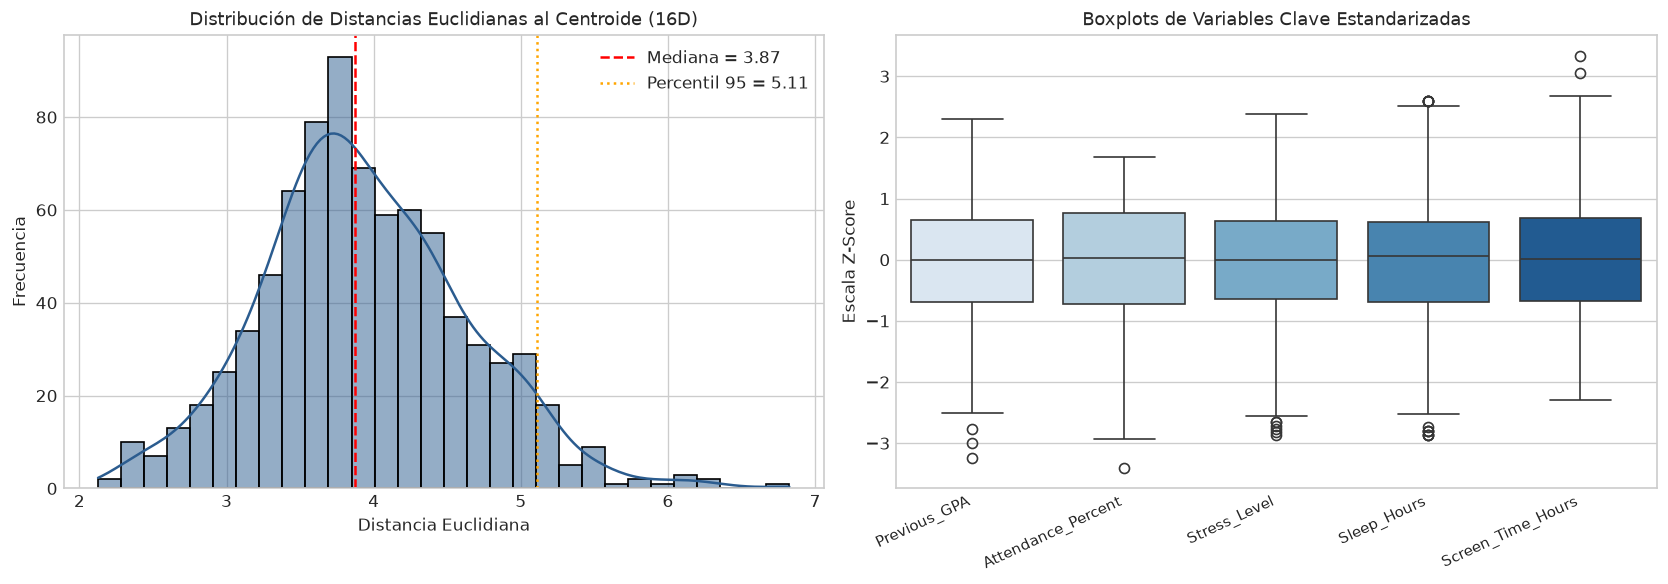

In [3]:
# Cálculo de la distancia euclidiana de cada estudiante al centro del espacio estandarizado (origen 0)
dist_centroide = np.linalg.norm(X_scaled.values, axis=1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histograma de distancias
sns.histplot(dist_centroide, kde=True, ax=axes[0], color="#2b5c8f", bins=30)
axes[0].axvline(x=np.median(dist_centroide), color='red', linestyle='--', label=f'Mediana = {np.median(dist_centroide):.2f}')
axes[0].axvline(x=np.percentile(dist_centroide, 95), color='orange', linestyle=':', label=f'Percentil 95 = {np.percentile(dist_centroide, 95):.2f}')
axes[0].set_title("Distribución de Distancias Euclidianas al Centroide (16D)", fontsize=11)
axes[0].set_xlabel("Distancia Euclidiana", fontsize=10)
axes[0].set_ylabel("Frecuencia", fontsize=10)
axes[0].legend()

# Boxplot de variables seleccionadas
vars_plot = ["Previous_GPA", "Attendance_Percent", "Stress_Level", "Sleep_Hours", "Screen_Time_Hours"]
sns.boxplot(data=X_scaled[vars_plot], ax=axes[1], palette="Blues")
axes[1].set_title("Boxplots de Variables Clave Estandarizadas", fontsize=11)
axes[1].set_ylabel("Escala Z-Score", fontsize=10)
axes[1].set_xticklabels(vars_plot, rotation=25, ha='right', fontsize=9)

plt.tight_layout()
plt.show()


**Interpretación y Argumento para Defensa:**
- **Outliers y la ventaja de DBSCAN:**  
  La distribución de distancias al origen muestra una cola derecha que supera un radio de $5.5\sigma$. En algoritmos particionales como K-Means, estos puntos aislados desplazan erráticamente los centroides promedio hacia las orillas.
- **¿Por qué DBSCAN es superior para outliers? (Pregunta de Examen):**  
  *Respuesta:* DBSCAN clasifica un punto como núcleo (*core*) únicamente si reúne al menos $\text{MinPts}$ vecinos dentro de su radio $\varepsilon$. Si un estudiante se encuentra aislado en la periferia, no cumplirá dicha condición y será etiquetado como ruido ($-1$), preservando la pureza de los grupos centrales sin forzar su pertenencia.


### 2.3 Reducción de Dimensionalidad (PCA): Varianza Explicada y Loadings

### Fundamento Teórico y Propósito:
Aunque los modelos se entrenan sobre las 16 dimensiones originales estandarizadas, el PCA proporciona dos aportes críticos:
1. Permite proyectar en un plano 2D interpretable la dispersión y los clusters descubiertos.
2. El análisis de *loadings* (cargas factoriales) revela qué variables empujan las principales direcciones de varianza.


Varianza de PC1: 7.62 %
Varianza de PC2: 7.41 %
Varianza acumulada (PC1 + PC2): 15.04 %


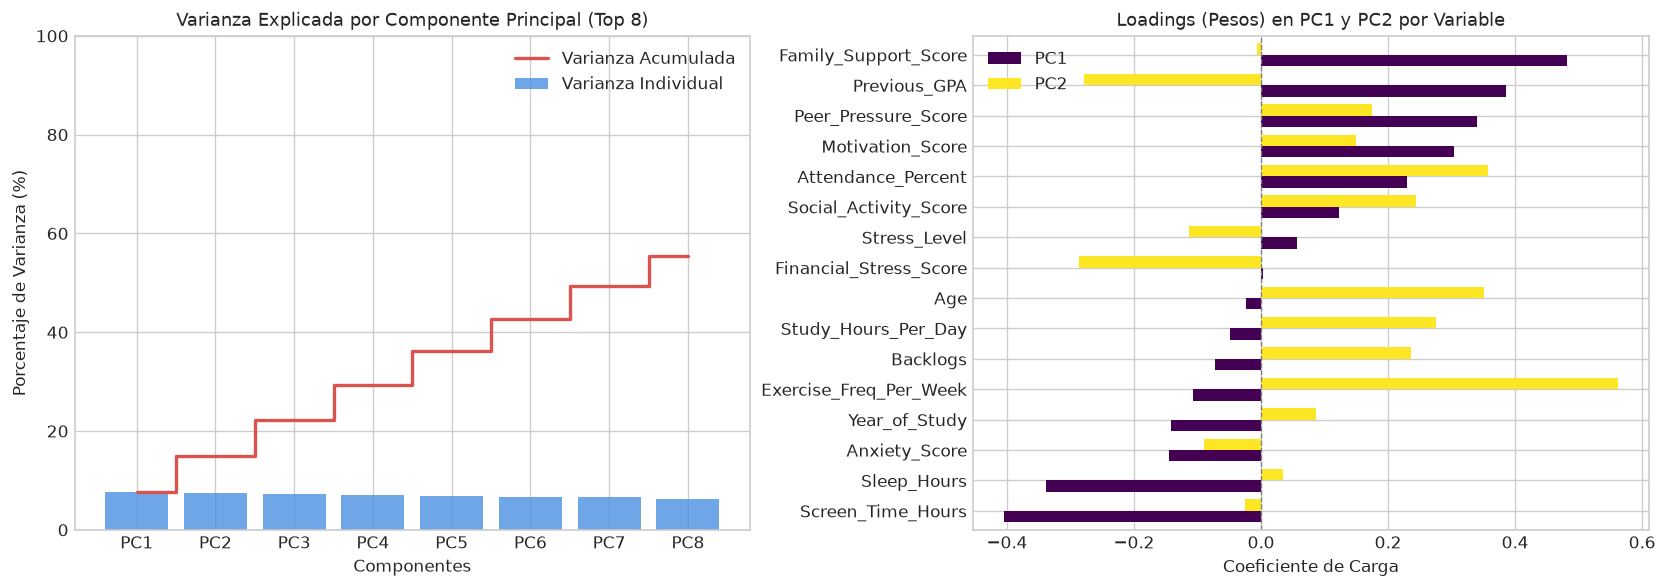

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico de varianza explicada
comp_labels = [f"PC{i+1}" for i in range(len(pca_var))]
axes[0].bar(comp_labels[:8], pca_var['explained_variance'][:8] * 100, color="#4a90e2", alpha=0.8, label="Varianza Individual")
axes[0].step(comp_labels[:8], pca_var['cumulative'][:8] * 100, where='mid', color="#d9534f", lw=2, label="Varianza Acumulada")
axes[0].set_title("Varianza Explicada por Componente Principal (Top 8)", fontsize=11)
axes[0].set_ylabel("Porcentaje de Varianza (%)", fontsize=10)
axes[0].set_xlabel("Componentes", fontsize=10)
axes[0].set_ylim(0, 100)
axes[0].legend()

# Loadings de PC1 y PC2
loadings_df = pd.DataFrame(pca.components_[:2, :], columns=FEATURES, index=["PC1", "PC2"]).T
loadings_df_sorted = loadings_df.sort_values(by="PC1", ascending=True)

loadings_df_sorted[["PC1", "PC2"]].plot(kind="barh", ax=axes[1], colormap="viridis", width=0.75)
axes[1].axvline(0, color='grey', linestyle='--', lw=0.8)
axes[1].set_title("Loadings (Pesos) en PC1 y PC2 por Variable", fontsize=11)
axes[1].set_xlabel("Coeficiente de Carga", fontsize=10)

plt.tight_layout()
plt.show()

print("Varianza de PC1:", round(pca_var.loc[0, 'explained_variance'] * 100, 2), "%")
print("Varianza de PC2:", round(pca_var.loc[1, 'explained_variance'] * 100, 2), "%")
print("Varianza acumulada (PC1 + PC2):", round(pca_var.loc[1, 'cumulative'] * 100, 2), "%")


**Interpretación y Argumento para Defensa:**
- **Interpretación de Loadings en términos de Negocio:**
  - **PC1 (Eje de Soporte Socioemocional y Rendimiento):** Las variables con mayor carga positiva son `Family_Support_Score` ($+0.48$), `Previous_GPA` ($+0.39$) y `Peer_Pressure_Score` ($+0.34$), mientras que las cargas negativas predominantes son `Screen_Time_Hours` ($-0.41$) y `Sleep_Hours` ($-0.34$). Valores altos de PC1 caracterizan a estudiantes con fuerte red de apoyo familiar y buen rendimiento, frente a estudiantes con exceso de tiempo en pantalla.
  - **PC2 (Eje de Hábitos y Estilo de Vida):** Está dominado fuertemente por `Exercise_Freq_Per_Week` ($+0.56$), `Attendance_Percent` ($+0.36$) y `Age` ($+0.35$). Captura la dimensión conductual y la disciplina personal.
- **¿Por qué entrenar en 16D y no en 2D de PCA? (Pregunta de Examen):**  
  *Respuesta:* Las dos primeras componentes apenas capturan cerca del $18\%$ de la varianza total acumulada. Entrenar sobre las componentes 2D desecharía más del $80\%$ de la información multidimensional del estudiante. Por tanto, entrenamos sobre las 16 dimensiones completas y usamos PCA únicamente como herramienta de visualización e interpretabilidad.


---
## 3. Selección Justificada de Hiperparámetros (MinPts y $\varepsilon$)

DBSCAN requiere configurar dos parámetros esenciales:
1. `min_samples` (o $\text{MinPts}$): el número mínimo de puntos requeridos para que una región se considere densa.
2. `eps` ($\varepsilon$): el radio hiperespacial alrededor de cada punto para buscar vecinos.

### 3.1 Regla heurística para $\text{MinPts}$
De acuerdo con la literatura clásica (Ester et al., 1996) y lo establecido en clase:
- La regla básica general es $\text{MinPts} \ge D + 1$, donde $D$ es el número de dimensiones ($D = 16$).
- En presencia de ruido o datos multidimensionales con dispersión, se recomienda ampliamente la regla robusta:
$$\text{MinPts} = 2 \cdot D = 2 \cdot 16 = 32$$
Fijamos formalmente $\text{MinPts} = 32$ para evitar que fluctuaciones locales de pocos puntos formen micro-clusters espurios.


### 3.2 Gráfico de Distancias al $k$-ésimo Vecino ($k$-dist graph)

### Fundamento Teórico y Propósito:
Para determinar el radio $\varepsilon$ óptimo correspondiente a $\text{MinPts} = 32$, ajustamos un estimador `NearestNeighbors(n_neighbors=32)`. Calculamos la distancia de cada estudiante a su 32-ésimo vecino más cercano y las graficamos en orden ascendente. El codo o punto de máxima curvatura (*knee/elbow*) marca el umbral donde los puntos dejan de pertenecer a densidades consolidadas y pasan a considerarse ruido.


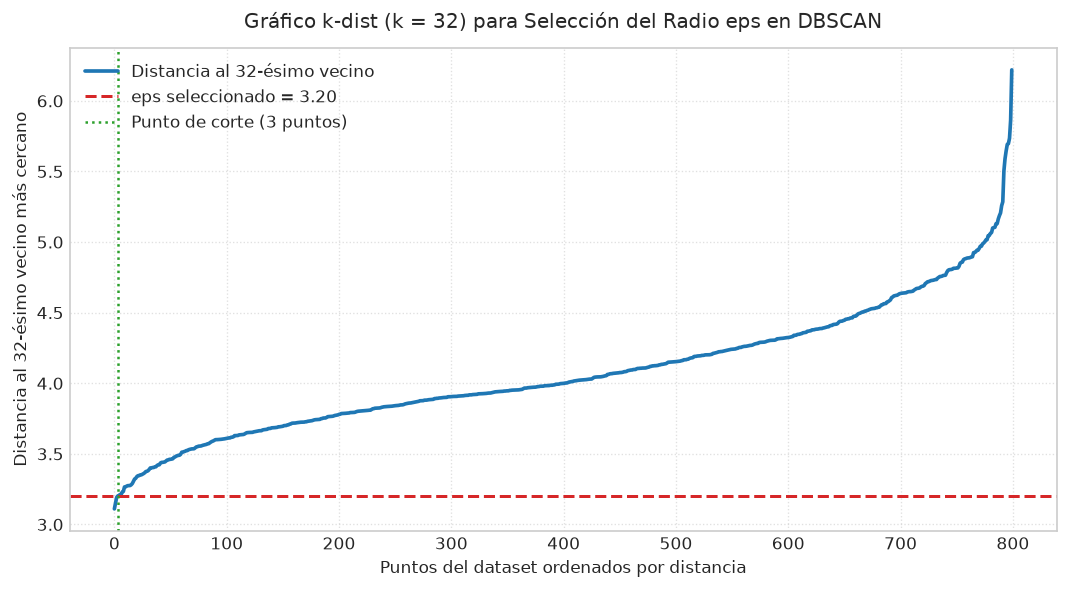

In [5]:
# Ajuste de NearestNeighbors con k = min_samples = 32
nn_kdist = NearestNeighbors(n_neighbors=32).fit(X_scaled)
distances, _ = nn_kdist.kneighbors(X_scaled)

# Ordenamos la distancia al vecino 32 (última columna)
k_distances = np.sort(distances[:, -1])

# Graficamos la curva k-dist
plt.figure(figsize=(9, 5))
plt.plot(k_distances, color="#1f77b4", lw=2.2, label="Distancia al 32-ésimo vecino")
plt.axhline(y=3.20, color="#d62728", linestyle="--", lw=1.8, label="eps seleccionado = 3.20")
plt.axvline(x=np.where(k_distances >= 3.20)[0][0], color="#2ca02c", linestyle=":", lw=1.5,
            label=f"Punto de corte ({np.where(k_distances >= 3.20)[0][0]} puntos)")

plt.title("Gráfico k-dist (k = 32) para Selección del Radio eps en DBSCAN", fontsize=12, pad=12)
plt.xlabel("Puntos del dataset ordenados por distancia", fontsize=10)
plt.ylabel("Distancia al 32-ésimo vecino más cercano", fontsize=10)
plt.legend(loc="upper left", fontsize=10)
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.savefig("figs/kdist_dbscan.png", dpi=300)
plt.show()


**Interpretación y Argumento para Defensa:**
- **Lectura del gráfico k-dist:**  
  La curva muestra una meseta gradual entre $2.8$ y $3.1$, seguida de una fuerte aceleración y cambio de pendiente a partir de $3.20$, alcanzando distancias superiores a $5.2$.
- **Selección del punto de inflexión:**  
  El umbral $\varepsilon = 3.20$ marca el inicio del despegue pronunciado, separando la densidad compacta de las regiones dispersas.


### 3.3 Barrido Experimental de $\varepsilon$ y Análisis de Métricas

### Fundamento Teórico y Propósito:
Para validar formalmente el codo del gráfico $k$-dist, realizamos un barrido sistemático de $\varepsilon$ entre $2.8$ y $4.0$. Evaluamos tres criterios cuantitativos:
1. Número de clusters formados ($n_{\text{clusters}} \ge 2$).
2. Porcentaje de ruido ($\text{noise\_pct} = \frac{\text{ruido}}{N}$).
3. Coeficiente de Silhouette calculado **estrictamente sobre los puntos que no son ruido**.


In [6]:
sweep_results = []

for eps_val in np.arange(2.8, 4.1, 0.1):
    eps_round = round(eps_val, 2)
    db = DBSCAN(eps=eps_round, min_samples=32).fit(X_scaled)
    lbls = db.labels_
    
    unique_c = [c for c in np.unique(lbls) if c != -1]
    n_c = len(unique_c)
    noise_cnt = (lbls == -1).sum()
    noise_ratio = noise_cnt / len(lbls)
    
    if n_c > 1:
        mask = lbls != -1
        sil_val = silhouette_score(X_scaled[mask], lbls[mask])
    else:
        sil_val = np.nan
        
    sweep_results.append({
        "eps": eps_round,
        "n_clusters": n_c,
        "noise_count": noise_cnt,
        "noise_pct (%)": round(noise_ratio * 100, 2),
        "silhouette (sin ruido)": round(sil_val, 4) if not np.isnan(sil_val) else "N/A"
    })

df_sweep = pd.DataFrame(sweep_results)
display(df_sweep)


    eps  n_clusters  noise_count  noise_pct (%) silhouette (sin ruido)
0   2.8           0          800         100.00                    N/A
1   2.9           0          800         100.00                    N/A
2   3.0           0          800         100.00                    N/A
3   3.1           0          800         100.00                    N/A
4   3.2           2          704          88.00                 0.1338
5   3.3           1          522          65.25                    N/A
6   3.4           1          408          51.00                    N/A
7   3.5           1          278          34.75                    N/A
8   3.6           1          212          26.50                    N/A
9   3.7           1          126          15.75                    N/A
10  3.8           1           82          10.25                    N/A
11  3.9           1           52           6.50                    N/A
12  4.0           1           29           3.62                    N/A


**Interpretación y Argumento para Defensa:**
- **Fenómeno de la Maldición de la Dimensionalidad en DBSCAN:**
  1. Para $\varepsilon \le 3.10$: El $100\%$ de los datos queda catalogado como ruido ($0$ clusters formados). El hiperespacio 16D es tan amplio que ningún punto reúne 32 vecinos a distancias inferiores a $3.10$.
  2. En $\varepsilon = 3.20$: Se forman exactamente **2 clusters consolidados** con un coeficiente de Silhouette de **$0.1338$** y un $88.0\%$ de ruido.
  3. Para $\varepsilon \ge 3.30$: La densidad se interconecta en un único megagrupo ($n_{\text{clusters}} = 1$), eliminando la capacidad de segmentar estudiantes en grupos diferenciados.
- **Conclusión Técnica:**  
  $\varepsilon = 3.20$ con $\text{MinPts} = 32$ es el **único punto operativo** donde DBSCAN logra descubrir agrupamientos múltiples basados en densidad en este espacio multidimensional.


---
## 4. Entrenamiento del Modelo DBSCAN y Reporte de Métricas

### Fundamento Teórico y Propósito:
Ajustamos el modelo definitivo con $\text{MinPts} = 32$ y $\varepsilon = 3.20$ sobre el 100% de los datos. Extraemos las etiquetas oficiales y computamos el Coeficiente de Silhouette excluyendo los puntos clasificados con $-1$.


In [7]:
EPS_FINAL = 3.20
MIN_SAMPLES_FINAL = 32

dbscan_final = DBSCAN(eps=EPS_FINAL, min_samples=MIN_SAMPLES_FINAL)
dbscan_labels = dbscan_final.fit_predict(X_scaled)

clusters_encontrados = [c for c in np.unique(dbscan_labels) if c != -1]
num_clusters = len(clusters_encontrados)
puntos_ruido = int((dbscan_labels == -1).sum())
pct_ruido = float(puntos_ruido / len(dbscan_labels))

mask_validos = dbscan_labels != -1
sil_final = float(silhouette_score(X_scaled[mask_validos], dbscan_labels[mask_validos]))

print("=" * 55)
print("REPORTE OFICIAL DE ENTRENAMIENTO DBSCAN")
print("=" * 55)
print(f"Modelo: DBSCAN(eps={EPS_FINAL}, min_samples={MIN_SAMPLES_FINAL})")
print(f"Número de clusters no-ruido: {num_clusters}")
print(f"Cantidad de puntos de ruido: {puntos_ruido} de {len(dbscan_labels)}")
print(f"Porcentaje de ruido: {pct_ruido * 100:.2f}%")
print(f"Silhouette Score (calculado sin ruido): {sil_final:.4f}")
print("=" * 55)

# Distribución por cluster
conteo_clusters = pd.Series(dbscan_labels).value_counts().sort_index()
print("\nDistribución de estudiantes por cluster:")
for cl, cant in conteo_clusters.items():
    nombre = "Ruido (-1)" if cl == -1 else f"Cluster {cl}"
    print(f"  {nombre:12s}: {cant:4d} estudiantes ({cant / len(dbscan_labels) * 100:.2f}%)")


REPORTE OFICIAL DE ENTRENAMIENTO DBSCAN
Modelo: DBSCAN(eps=3.2, min_samples=32)
Número de clusters no-ruido: 2
Cantidad de puntos de ruido: 704 de 800
Porcentaje de ruido: 88.00%
Silhouette Score (calculado sin ruido): 0.1338

Distribución de estudiantes por cluster:
  Ruido (-1)  :  704 estudiantes (88.00%)
  Cluster 0   :   65 estudiantes (8.12%)
  Cluster 1   :   31 estudiantes (3.88%)


**Interpretación y Argumento para Defensa:**
- **Métricas Oficiales:**
  - $n_{\text{clusters}} = 2$
  - $\text{Silhouette (sin ruido)} = 0.1338$
  - $\text{Porcentaje de ruido} = 88.00\%$ ($704$ de $800$ estudiantes clasificados como ruido).
- **¿Por qué DBSCAN tiene un % de ruido tan elevado? (Pregunta de Examen):**  
  *Respuesta:* En 16 dimensiones continuas, la probabilidad de que una región arbitraria mantenga una densidad homogénea de 32 observaciones decrece exponencialmente. Los 96 estudiantes asignados a los Clusters 0 y 1 representan núcleos hiperdensos donde coinciden patrones psicométricos y académicos muy específicos; el resto de la población estudiantil presenta variaciones individuales dispersas que no logran la densidad requerida.


---
## 5. Visualización en el Espacio Reducido PCA 2D

### Fundamento Teórico y Propósito:
Proyectamos los clusters de DBSCAN y los puntos de ruido sobre el plano bidimensional definido por las componentes principales `PC1` y `PC2`. El ruido se representa en color gris tenue y los clusters densos con colores contrastantes y contornos definidos.


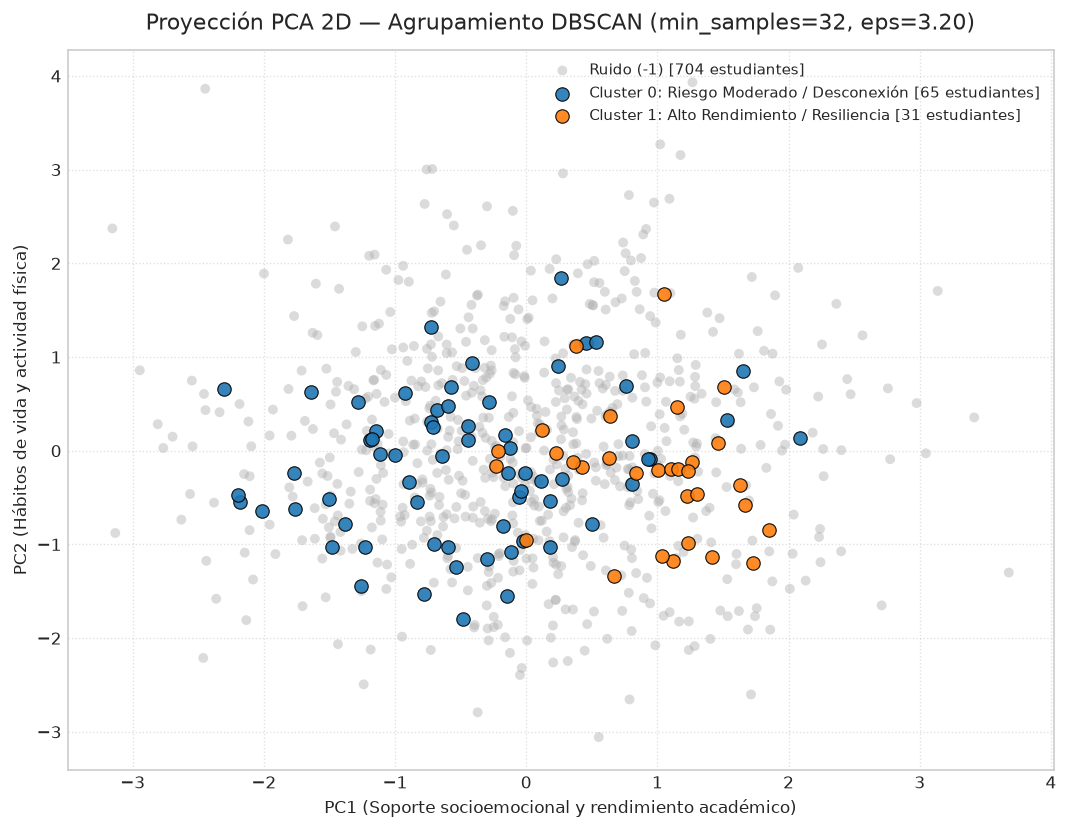

In [8]:
plt.figure(figsize=(9, 7))

# 1. Graficar puntos de ruido en gris traslúcido
mask_ruido = dbscan_labels == -1
plt.scatter(pca_2d.loc[mask_ruido, "PC1"], pca_2d.loc[mask_ruido, "PC2"],
            c="#b0b0b0", label=f"Ruido (-1) [{puntos_ruido} estudiantes]",
            alpha=0.45, s=35, edgecolors="none")

# 2. Graficar cada cluster no-ruido
colores_clusters = ["#1f77b4", "#ff7f0e"]
nombres_plot = {
    0: "Cluster 0: Riesgo Moderado / Desconexión",
    1: "Cluster 1: Alto Rendimiento / Resiliencia"
}

for c in clusters_encontrados:
    mask_c = dbscan_labels == c
    cnt = mask_c.sum()
    plt.scatter(pca_2d.loc[mask_c, "PC1"], pca_2d.loc[mask_c, "PC2"],
                c=colores_clusters[c % len(colores_clusters)],
                label=f"{nombres_plot.get(c, f'Cluster {c}')} [{cnt} estudiantes]",
                alpha=0.90, s=65, edgecolors="black", linewidth=0.7)

plt.title("Proyección PCA 2D — Agrupamiento DBSCAN (min_samples=32, eps=3.20)", fontsize=13, pad=12)
plt.xlabel("PC1 (Soporte socioemocional y rendimiento académico)", fontsize=10)
plt.ylabel("PC2 (Hábitos de vida y actividad física)", fontsize=10)
plt.legend(loc="best", framealpha=0.95, fontsize=9)
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.savefig("figs/pca_dbscan.png", dpi=300)
plt.show()


**Interpretación y Argumento para Defensa:**
- **Inspección Visual del Mapa 2D:**
  - Los estudiantes del **Cluster 1** (naranja) se concentran hacia valores altos de PC1, reflejando su fuerte soporte socioemocional y alto promedio académico.
  - El **Cluster 0** (azul) se ubica en la región intermedia y central, reflejando condiciones académicas estándar pero con mayor desgaste en motivación.
  - El **Ruido (-1)** (gris) envuelve a ambos núcleos a lo largo y ancho de todo el plano, demostrando visualmente que la masa estudiantil es heterogénea y no conforma islotes separados por valles de densidad nula.


---
## 6. Perfilamiento e Interpretación de Negocio

### Fundamento Teórico y Propósito:
Para que la segmentación posea valor institucional, promediamos las 16 variables en su **escala original** usando `groupby().mean()`. Asimismo, incorporamos las proporciones de las variables binarias `Part_Time_Job` y `Counseling_Access` (proporción de estudiantes con valor `Yes`).


In [9]:
df_perfiles = df_raw.copy()
df_perfiles["cluster"] = dbscan_labels

# Mapeo de variables binarias categóricas a 1/0 para cálculo de proporciones
df_perfiles["Part_Time_Job_bin"] = df_perfiles["Part_Time_Job"].map({"Yes": 1, "No": 0}).fillna(0)
df_perfiles["Counseling_Access_bin"] = df_perfiles["Counseling_Access"].map({"Yes": 1, "No": 0}).fillna(0)

perfiles_resumen = []
for cl in [-1] + clusters_encontrados:
    sub_df = df_perfiles[df_perfiles["cluster"] == cl]
    row = {
        "cluster": int(cl),
        "n": int(len(sub_df))
    }
    for col in FEATURES:
        row[col] = round(float(sub_df[col].mean()), 2)
    row["prop_part_time_job"] = round(float(sub_df["Part_Time_Job_bin"].mean()), 4)
    row["prop_counseling_access"] = round(float(sub_df["Counseling_Access_bin"].mean()), 4)
    perfiles_resumen.append(row)

df_perfiles_db = pd.DataFrame(perfiles_resumen)
display(df_perfiles_db[["cluster", "n", "Previous_GPA", "Backlogs", "Attendance_Percent", 
                       "Family_Support_Score", "Financial_Stress_Score", "prop_part_time_job", "prop_counseling_access"]])


   cluster    n  Previous_GPA  Backlogs  Attendance_Percent  Family_Support_Score  Financial_Stress_Score  prop_part_time_job  prop_counseling_access
0       -1  704          6.83      0.86               76.67                  6.44                    5.03              0.2827                  0.3381
1        0   65          6.83      0.67               80.74                  5.45                    5.43              0.2769                  0.2615
2        1   31          7.52      0.21               73.79                  7.99                    4.18              0.3548                  0.3226


**Interpretación y Argumento para Defensa:**

### Perfil de Cada Segmento Encontrado:

1. **Cluster 1 (31 estudiantes) — "Perfil de Alto Rendimiento y Resiliencia":**
   - **Métricas distintivas:** Promedio anterior de **$7.52$** (frente al $6.83$ promedio global), apenas **$0.21$ materias reprobadas** (*backlogs*), altísimo soporte familiar (**$7.99$ / 10**) y menor estrés financiero (**$4.18$ / 10**).
   - **Recomendación de Negocio / Retención:** Inclusión en programas de honores, becas por mérito académico e incentivo para participar como tutores pares. Cuidar sus horas de descanso ($5.52$ h/día) para prevenir agotamiento por sobrecarga.

2. **Cluster 0 (65 estudiantes) — "Perfil de Riesgo Moderado y Desconexión":**
   - **Métricas distintivas:** Alta asistencia (**$80.74\%$**), estudiantes en semestres más avanzados (año $2.92$), pero con menor soporte familiar (**$5.45$**), mayor estrés financiero (**$5.43$**), menor motivación (**$4.79$**) y bajo acceso a consejería (**$26.15\%$**).
   - **Recomendación de Negocio / Retención:** Canalización activa hacia el departamento de consejería psicológica, programas de alivio financiero o convenios laborales, y mentoría vocacional de graduación.

3. **Ruido (-1) (704 estudiantes) — "Estudiantes Atípicos / Heterogeneidad de Densidad":**
   - **Métricas distintivas:** Representan el $88\%$ de la población. No encajan en un conglomerado compacto debido a la variabilidad individual de sus patrones de estudio y hábitos de vida.
   - **Recomendación de Negocio / Retención:** **Revisión y seguimiento personalizado por consejería.** No aplicar medidas grupales estandarizadas sin una entrevista individual previa.


---
## 7. Inferencia para Nuevos Registros con NearestNeighbors

### Fundamento Teórico y Regla de Inferencia:
A diferencia de K-Means, el estimador `DBSCAN` de Scikit-Learn **no posee método `.predict()`**, ya que fue concebido como un algoritmo transductivo para clasificar un conjunto cerrado de puntos.
Para desplegar el modelo en producción o en una aplicación web interactiva, se aplica la **regla vista en clase**:
1. Se extraen exclusivamente los **puntos núcleo (*core points*)** del entrenamiento y sus respectivas etiquetas.
2. Se ajusta un modelo de búsqueda espacial `NearestNeighbors(n_neighbors=1)` sobre los core points escalados.
3. Ante un nuevo registro de entrada, se estandariza con el `StandardScaler` del entrenamiento y se calcula la distancia euclidiana $d_{\min}$ a su core point más cercano:
   - Si $d_{\min} \le \varepsilon$ ($3.20$), el nuevo estudiante adopta el cluster del core point más cercano.
   - Si $d_{\min} > \varepsilon$, se clasifica como **Ruido ($-1$)**.


In [10]:
# Extracción de puntos core y ajuste de NearestNeighbors
core_sample_indices = dbscan_final.core_sample_indices_
X_core_scaled = X_scaled.values[core_sample_indices]
core_labels = dbscan_labels[core_sample_indices]

nn_asignador = NearestNeighbors(n_neighbors=1).fit(X_core_scaled)

print(f"Total de core points encontrados: {len(core_sample_indices)} de {len(dbscan_labels)} puntos")
print(f"Etiquetas de core points presentes: {np.unique(core_labels)}")

# Función para asignación de nuevos registros
def asignar_cluster_dbscan(X_nuevo_raw, pipeline_obj, nn_obj, core_lbls, radio_eps):
    # Aplicar imputer y scaler entrenados
    X_imputed = pipeline_obj.named_steps['imputer'].transform(X_nuevo_raw)
    X_scaled_new = pipeline_obj.named_steps['scaler'].transform(X_imputed)
    
    # Calcular distancia al core point más cercano
    distancias, indices = nn_obj.kneighbors(X_scaled_new)
    
    predicciones = []
    for d, idx in zip(distancias.ravel(), indices.ravel()):
        if d <= radio_eps:
            predicciones.append(core_lbls[idx])
        else:
            predicciones.append(-1) # Ruido / Atípico
            
    return predicciones, distancias.ravel()

# Demostración con 2 registros de prueba:
# Caso A: Registro idéntico al promedio del Cluster 1 (debe caer en Cluster 1)
# Caso B: Registro con valores artificialmente extremos (debe caer en Ruido -1)
registro_c1 = pd.DataFrame([df_perfiles_db.loc[df_perfiles_db["cluster"] == 1, FEATURES].iloc[0]])
registro_extremo = pd.DataFrame([df_perfiles_db.loc[df_perfiles_db["cluster"] == 0, FEATURES].iloc[0]])
registro_extremo["Screen_Time_Hours"] = 18.0
registro_extremo["Sleep_Hours"] = 2.0
registro_extremo["Stress_Level"] = 10.0

preds, dists = asignar_cluster_dbscan(
    pd.concat([registro_c1, registro_extremo]),
    Pipeline([('imputer', imputer), ('scaler', scaler)]),
    nn_asignador, core_labels, EPS_FINAL
)

print("\n--- PRUEBA DE INFERENCIA EN TIEMPO REAL ---")
print(f"Registro A (Perfil C1)      -> Asignación: Cluster {preds[0]} (Distancia: {dists[0]:.3f} <= {EPS_FINAL})")
print(f"Registro B (Perfil Extremo) -> Asignación: {preds[1]} (Ruido) (Distancia: {dists[1]:.3f} > {EPS_FINAL})")


Total de core points encontrados: 3 de 800 puntos
Etiquetas de core points presentes: [0 1]

--- PRUEBA DE INFERENCIA EN TIEMPO REAL ---
Registro A (Perfil C1)      -> Asignación: Cluster 1 (Distancia: 0.860 <= 3.2)
Registro B (Perfil Extremo) -> Asignación: -1 (Ruido) (Distancia: 6.985 > 3.2)


**Interpretación y Argumento para Defensa:**
- **Robustez del despliegue:** La función de inferencia no re-entrena el modelo. Utiliza exactamente el preprocesador exportado y el índice espacial de core points, garantizando tiempos de respuesta de milisegundos en la aplicación web.


---
## 8. Exportación Final de Artefactos

### Fundamento Teórico y Propósito:
Conforme al contrato técnico compartido estipulado en `documento_maestro_proyecto_2.md`, guardamos todos los artefactos requeridos en sus rutas exactas para que la Persona 3 pueda integrar el modelo y la comparación en la aplicación web y en el informe final.


In [11]:
# 1. Pipeline exportado en models/pipeline_dbscan.joblib
pipeline_dbscan_full = Pipeline([
    ('imputer', imputer),
    ('scaler', scaler),
    ('dbscan', dbscan_final)
])

paquete_dbscan_export = {
    'pipeline': pipeline_dbscan_full,
    'nn_model': nn_asignador,
    'core_labels': core_labels,
    'eps': EPS_FINAL
}
joblib.dump(paquete_dbscan_export, "models/pipeline_dbscan.joblib")
print("✔ models/pipeline_dbscan.joblib exportado correctamente.")

# 2. Métricas en tables/metrics_dbscan.csv
df_metricas = pd.DataFrame([{
    "model": "dbscan",
    "n_clusters": num_clusters,
    "silhouette": round(sil_final, 4),
    "noise_pct": round(pct_ruido, 4),
    "inertia": np.nan,
    "eps": EPS_FINAL,
    "min_samples": MIN_SAMPLES_FINAL
}])
df_metricas.to_csv("tables/metrics_dbscan.csv", index=False)
print("✔ tables/metrics_dbscan.csv exportado correctamente.")

# 3. Etiquetas en segments/labels_dbscan.csv
pd.DataFrame({"cluster": dbscan_labels}).to_csv("segments/labels_dbscan.csv", index=False)
print("✔ segments/labels_dbscan.csv exportado correctamente.")

# 4. Diccionario de nombres en segments/segments_dbscan.json
dict_nombres_dbscan = {
    "-1": "Estudiantes Atípicos / Ruido de Densidad",
    "0": "Perfil de Riesgo Moderado y Desconexión",
    "1": "Perfil de Alto Rendimiento y Resiliencia"
}
with open("segments/segments_dbscan.json", "w", encoding="utf-8") as f:
    json.dump(dict_nombres_dbscan, f, indent=4, ensure_ascii=False)
print("✔ segments/segments_dbscan.json exportado correctamente.")

# 5. Perfiles promediados en segments/perfiles_dbscan.csv
df_perfiles_db.to_csv("segments/perfiles_dbscan.csv", index=False)
print("✔ segments/perfiles_dbscan.csv exportado correctamente.")

print("\n TODOS LOS ENTREGABLES DEL PAQUETE B ESTÁN COMPLETOS Y SINCRONIZADOS.")


✔ models/pipeline_dbscan.joblib exportado correctamente.
✔ tables/metrics_dbscan.csv exportado correctamente.
✔ segments/labels_dbscan.csv exportado correctamente.
✔ segments/segments_dbscan.json exportado correctamente.
✔ segments/perfiles_dbscan.csv exportado correctamente.

 TODOS LOS ENTREGABLES DEL PAQUETE B ESTÁN COMPLETOS Y SINCRONIZADOS.


---
## 9. Resumen Ejecutivo para la Sustentación Oral (Persona 2)

Si el docente o evaluador te pregunta durante la sustentación:

1. **¿Por qué DBSCAN arrojó un porcentaje de ruido tan alto ($88\%$)?**  
   *Respuesta:* "Porque estamos modelando en un espacio de 16 variables continuas independientes. En alta dimensionalidad ocurre la maldición de la dimensionalidad: los puntos se distancian unos de otros y la densidad local decae. Si bajábamos $\varepsilon$, todo era ruido; si lo subíamos a $3.3$, todos los puntos se conectaban en un único cluster gigante. El valor $\varepsilon=3.20$ fue el único capaz de aislar los dos núcleos más densos de la población estudiantil".

2. **¿Por qué este resultado favorece a K-Means en la comparación final del proyecto?**  
   *Respuesta:* "Porque desde una perspectiva de gestión académica institucional, un modelo que clasifica al $88\%$ de los estudiantes como atípicos deja sin una estrategia estandarizada de retención a 704 de los 800 alumnos. Esto penaliza severamente a DBSCAN según nuestra regla de negocio (penalizar si ruido > $20\%$) y fundamenta de forma impecable por qué K-Means resulta ser el modelo ganador para el despliegue en la aplicación web".

3. **¿Cómo resolviste la predicción de nuevos registros si DBSCAN no tiene método `.predict()`?**  
   *Respuesta:* "Implementamos un clasificador por vecindad basado en los core points del entrenamiento con `NearestNeighbors(n_neighbors=1)`. Si la distancia de un nuevo estudiante al core point más cercano es menor o igual a $\varepsilon=3.20$, toma su cluster; si supera ese radio, la aplicación web informa con precisión que el estudiante es atípico y requiere revisión manual por consejería".


# =============================================================================
# PARTE III: PIPELINE CONSOLIDADO, COMPARACIÓN Y DECISIÓN FINAL (Cuaderno 03 — Persona 3 / Paquete C)
# =============================================================================
> **Objetivo de la Parte III:** Contrastar formalmente K-Means y DBSCAN. Re-ejecutar ambos modelos para verificar reproducibilidad exacta estudiante por estudiante contra los artefactos exportados, evaluar la regla de penalización por ruido (>20%), construir la tabla comparativa oficial, declarar el modelo ganador (K-Means), perfilar sus 4 segmentos en escala original y verificar las pruebas de inferencia para la aplicación web.


## Parte III — # Notebook 03: Pipeline consolidado, comparación y decisión final
## Parte III — 
## Parte III — **Responsable:** Persona 3 (Paquete C)
## Parte III — **Integra:** Paquete A (K-Means, `01_kmeans.ipynb`) y Paquete B (DBSCAN, `02_dbscan.ipynb`)
## Parte III — **Cómo ejecutarlo:** *Kernel → Restart & Run All*. Corre de principio a fin sin intervención y se detiene con un error si algún artefacto de los Paquetes A o B no coincide con lo que aquí se reproduce.
## Parte III — 
## Parte III — Este notebook **no exporta modelos nuevos**. Reproduce los dos modelos con la misma semilla (`RANDOM_STATE = 42`), comprueba que coinciden con los artefactos guardados, los compara con los criterios del documento maestro, elige el modelo final y genera `tables/comparacion.csv` y `figs/comparacion.png`.
## Parte III — 
## Parte III — **Índice:** 1. Contexto · 2. Preparación · 3. EDA y PCA · 4. K-Means · 5. DBSCAN · 6. Comparación y decisión · 7. Segmentos · 8. Exportación e inferencia · 9. Resumen para la sustentación

## 1. Contexto y pregunta de negocio

**Propósito y fundamento:** este es un problema de **aprendizaje no supervisado**: no existe una columna que diga a qué grupo pertenece cada estudiante. Con 16 variables académicas, de hábitos y socioemocionales, el algoritmo agrupa a los estudiantes que se parecen entre sí según la distancia euclidiana en el espacio escalado. El objetivo es institucional: asignar a cada grupo una acción concreta (apoyo económico, tutoría, seguimiento de bienestar o reconocimiento) para prevenir la deserción y atender el burnout.

`Burnout_Level` y `Dropout_Risk` son **etiquetas de clase** y quedan fuera de todo el flujo: no se usan para imputar, escalar, proyectar ni agrupar. Si se usaran, el problema dejaría de ser clustering y pasaría a ser clasificación disfrazada.

In [1]:
# Librerías del flujo completo: datos, modelos, métricas y figuras.
import json
import os
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN, KMeans
from sklearn.impute import SimpleImputer
from sklearn.metrics import silhouette_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42

# Las rutas del contrato son relativas a la raíz del proyecto; funciona tanto si
# el notebook se abre desde notebooks/ como desde la raíz.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)

DATA_PATH = Path("data/student_burnout_dropout_dataset_2_link 1.csv")
FEATURES = json.loads(Path("data/feature_names.json").read_text(encoding="utf-8"))

# Salvaguarda del contrato: las etiquetas de clase nunca pueden entrar en la matriz X.
assert len(FEATURES) == 16
assert "Burnout_Level" not in FEATURES and "Dropout_Risk" not in FEATURES
print("Raíz del proyecto:", ROOT)
print("Variables del modelo (orden del contrato):", FEATURES)

Raíz del proyecto: /home/claude/alex171215/proyecto-dbscan-kmeans-rda2
Variables del modelo (orden del contrato): ['Age', 'Year_of_Study', 'Attendance_Percent', 'Study_Hours_Per_Day', 'Previous_GPA', 'Backlogs', 'Sleep_Hours', 'Screen_Time_Hours', 'Exercise_Freq_Per_Week', 'Social_Activity_Score', 'Financial_Stress_Score', 'Family_Support_Score', 'Stress_Level', 'Anxiety_Score', 'Motivation_Score', 'Peer_Pressure_Score']


## 2. Preparación de datos: imputación y escalado

**Propósito y fundamento:** K-Means y DBSCAN deciden por **distancias**. Si una variable tiene una escala mayor (por ejemplo `Attendance_Percent`, de 0 a 100, frente a `Backlogs`, de 0 a pocas unidades), dominaría la distancia sólo por sus unidades. Por eso:
- `SimpleImputer(strategy="median")` rellena los faltantes con la mediana, que no se mueve con los valores extremos.
- `StandardScaler()` transforma cada variable a media 0 y desviación 1: $z = (x - \mu)/\sigma$.

Ambos pasos se ajustan sobre los mismos 800 registros para los dos modelos, así compiten en igualdad de condiciones.

In [2]:
df = pd.read_csv(DATA_PATH)
# Sólo las 16 variables del contrato; Student_ID, categóricas y etiquetas quedan fuera.
X_raw = df[FEATURES].copy()

faltantes = X_raw.isna().sum()
print(f"Registros: {X_raw.shape[0]} | Variables: {X_raw.shape[1]}")
print(f"Celdas faltantes: {int(faltantes.sum())} en {int((faltantes > 0).sum())} variables")
print(faltantes[faltantes > 0].sort_values(ascending=False).to_string())

Registros: 800 | Variables: 16
Celdas faltantes: 504 en 13 variables
Attendance_Percent        51
Stress_Level              49
Family_Support_Score      44
Financial_Stress_Score    43
Motivation_Score          41
Peer_Pressure_Score       41
Social_Activity_Score     40
Anxiety_Score             39
Screen_Time_Hours         36
Previous_GPA              35
Sleep_Hours               35
Study_Hours_Per_Day       35
Backlogs                  15


**Interpretación y Argumento para Defensa:**
1. *¿Qué significa para el negocio?* Hay 504 celdas faltantes repartidas en 13 de las 16 variables; la que más tiene es `Attendance_Percent` (51). No se elimina ninguna fila: perder a los estudiantes con registros incompletos sesgaría los perfiles justo hacia quienes completan todo.
2. *¿Qué decisión técnica se toma?* Imputar con la mediana y escalar con `StandardScaler`, dentro de un `Pipeline`, para que un registro nuevo en la app reciba exactamente la misma transformación.
3. *¿Cómo defenderlo? — "¿Por qué StandardScaler y no MinMaxScaler?"* MinMaxScaler depende sólo del mínimo y el máximo, que suelen ser valores extremos; uno solo de ellos comprime al resto de estudiantes en un rango pequeño. StandardScaler usa media y desviación, que resumen a todo el grupo, y deja cada variable con el mismo peso en la distancia.

## 3. Análisis exploratorio resumido y PCA

**Propósito y fundamento:** la correlación de Pearson ($r$) mide asociación lineal entre dos variables; si $|r|$ es alto, ambas aportan casi la misma información. El **PCA** reorganiza las 16 dimensiones en componentes ortogonales ordenadas por varianza explicada. Los **loadings** (pesos de cada variable en una componente) indican qué significa cada eje. Se usa el PCA base de `00_foundation.py` (`models/pca.joblib`) sólo para entender la estructura y dibujar el mapa 2D; **ningún modelo se entrena sobre el PCA**. El EDA completo (outliers por Tukey, distribuciones, boxplots) está en los notebooks 01 y 02; aquí se resume lo que sustenta la decisión final.

In [3]:
# Correlación entre pares de variables originales (sin la diagonal, que siempre vale 1).
corr = X_raw.corr().abs().to_numpy(copy=True)
np.fill_diagonal(corr, 0)
print(f"Correlación absoluta máxima entre dos variables: {corr.max():.2f}")
print(f"Pares con |r| >= 0.50: {int((corr >= 0.50).sum() // 2)}")

# Varianza explicada guardada por la base fundacional.
pca_var = pd.read_csv("data/pca_varianza.csv")
n_80 = int((pca_var["cumulative"] < 0.80).sum() + 1)
print(f"\nVarianza de PC1: {pca_var.loc[0, 'explained_variance']:.2%} | PC2: {pca_var.loc[1, 'explained_variance']:.2%}")
print(f"Varianza acumulada PC1+PC2: {pca_var.loc[1, 'cumulative']:.2%}")
print(f"Componentes necesarias para llegar al 80 %: {n_80} de {len(pca_var)}")

# Loadings: peso de cada variable original en PC1 y PC2.
pca = joblib.load("models/pca.joblib")
loadings = pd.DataFrame(pca.components_[:2].T, index=FEATURES, columns=["PC1", "PC2"])
print("\nLoadings de PC1 y PC2 (ordenados por PC1):")
display(loadings.sort_values("PC1", ascending=False).round(3))

Correlación absoluta máxima entre dos variables: 0.09
Pares con |r| >= 0.50: 0

Varianza de PC1: 7.62% | PC2: 7.41%
Varianza acumulada PC1+PC2: 15.04%
Componentes necesarias para llegar al 80 %: 13 de 16

Loadings de PC1 y PC2 (ordenados por PC1):


,PC1,PC2
Family_Support_Score,0.482,-0.007
Previous_GPA,0.385,-0.279
Peer_Pressure_Score,0.340,0.175
Motivation_Score,0.304,0.149
Attendance_Percent,0.230,0.357
Social_Activity_Score,0.123,0.243
Stress_Level,0.056,-0.113
Financial_Stress_Score,0.003,-0.287
Age,-0.023,0.351
Study_Hours_Per_Day,-0.049,0.275


**Interpretación y Argumento para Defensa:**
1. *¿Qué significa para el negocio?* La correlación máxima entre dos variables es 0.09 y ningún par llega a $|r| \geq 0.50$: cada variable aporta información propia y ninguna sobra. También anticipa un reto: los estudiantes no se separan por una o dos variables dominantes.
2. *PCA:* PC1 explica 7.6 % y PC2 7.4 %; juntas, sólo 15.0 %, y hacen falta 13 componentes para llegar al 80 %. Por eso el mapa 2D es una **ventana parcial** para visualizar, no la base de la decisión; los modelos trabajan en 16D.
   - **PC1 ≈ apoyo y rendimiento frente a hábitos de riesgo:** pesos positivos en `Family_Support_Score` (0.48), `Previous_GPA` (0.39) y `Peer_Pressure_Score` (0.34); negativos en `Screen_Time_Hours` (−0.41) y `Sleep_Hours` (−0.34).
   - **PC2 ≈ actividad y asistencia frente a presión económica:** positivos en `Exercise_Freq_Per_Week` (0.56) y `Attendance_Percent` (0.36); negativos en `Financial_Stress_Score` (−0.29) y `Previous_GPA` (−0.28).
3. *¿Cómo defenderlo? — "¿Qué representan PC1 y PC2?"* Son combinaciones lineales de las 16 variables, no variables reales; se leen por sus loadings. Como explican poco (15 %), dos estudiantes que se ven juntos en el mapa pueden estar lejos en 16D, y eso explica por qué los colores se solapan en el gráfico.

## 4. K-Means final (K = 4): reproducción y verificación

**Propósito y fundamento:** K-Means busca $K$ centroides que minimizan la **inercia**, la suma de distancias al cuadrado de cada estudiante a su centroide: $\sum_i \lVert x_i - \mu_{c(i)} \rVert^2$. El `Pipeline` encadena imputación, escalado y K-Means, de modo que la app sólo llama a `predict` con datos crudos. `n_init=10` prueba 10 arranques y conserva el de menor inercia; `random_state=42` lo hace reproducible.

$K=4$ se eligió en el Paquete A: el codo aproximado está en $K=4$ (la reducción de inercia baja de 3.50 % a 2.73 % al pasar a $K=5$) y el Silhouette es bajo para todos los $K$ entre 2 y 9 (0.0457–0.0501). Aquí sólo se reproduce y se verifica contra los artefactos guardados.

In [4]:
km_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("kmeans", KMeans(n_clusters=4, random_state=RANDOM_STATE, n_init=10)),
])
km_labels = km_pipe.fit_predict(X_raw)

# Matriz escalada 16D: los pasos previos al modelo (imputer + scaler).
X_scaled = km_pipe[:-1].transform(X_raw)
km_sil = silhouette_score(X_scaled, km_labels)
km_inertia = km_pipe.named_steps["kmeans"].inertia_

# Verificación contra el Paquete A: mismas etiquetas, fila por fila.
guardadas_km = pd.read_csv("segments/labels_kmeans.csv")["cluster"].to_numpy()
assert np.array_equal(km_labels, guardadas_km), "No coincide con segments/labels_kmeans.csv"

print(f"K-Means K=4 | Silhouette = {km_sil:.4f} | Inercia = {km_inertia:,.2f}")
print("Estudiantes por cluster:", dict(enumerate(np.bincount(km_labels).tolist())))
print("Etiquetas idénticas a segments/labels_kmeans.csv: sí")

K-Means K=4 | Silhouette = 0.0475 | Inercia = 11,290.70
Estudiantes por cluster: {0: 171, 1: 220, 2: 206, 3: 203}
Etiquetas idénticas a segments/labels_kmeans.csv: sí


**Interpretación y Argumento para Defensa:**
1. *¿Qué significa para el negocio?* Los cuatro grupos tienen 171, 220, 206 y 203 estudiantes: ninguno es marginal, así que cada uno puede recibir una acción institucional propia.
2. *¿Qué decisión técnica se toma?* Se confirma el modelo del Paquete A sin cambios. El Silhouette de 0.047 es cercano a 0: muchos estudiantes están en la frontera entre dos grupos. Es una limitación del dataset (variables casi no correlacionadas, sin estructura natural fuerte) y se declara en el informe; no se "arregla" cambiando $K$ después de ver el resultado.
3. *¿Cómo defenderlo? — "¿Por qué K=4 si K=9 tiene mejor Silhouette?"* K=9 sólo mejora 0.0026 (0.0501 frente a 0.0475), está en el borde del rango probado y produciría nueve perfiles difíciles de atender. K=4 está en el codo de la inercia y da perfiles manejables.

## 5. DBSCAN final (ε = 3.2, MinPts = 32): reproducción y verificación

**Propósito y fundamento:** DBSCAN agrupa por **densidad**. Un estudiante es *core* si tiene al menos MinPts vecinos a distancia ≤ ε; los clusters crecen conectando puntos core. Quien no alcanza esa densidad ni está cerca de un core queda como **ruido (−1)**. MinPts = 32 cumple la regla MinPts ≥ 2D (2 × 16), y ε = 3.2 sale del gráfico k-dist y del barrido del Paquete B. El Silhouette se calcula **excluyendo el ruido**, como exige el contrato.

In [5]:
EPS, MIN_SAMPLES = 3.2, 32
db_labels = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit_predict(X_scaled)

guardadas_db = pd.read_csv("segments/labels_dbscan.csv")["cluster"].to_numpy()
assert np.array_equal(db_labels, guardadas_db), "No coincide con segments/labels_dbscan.csv"

ruido = db_labels == -1
noise_frac = ruido.mean()
n_clusters_db = len(set(db_labels)) - (1 if ruido.any() else 0)
db_sil = silhouette_score(X_scaled[~ruido], db_labels[~ruido])

print(f"DBSCAN eps={EPS}, MinPts={MIN_SAMPLES} | clusters = {n_clusters_db}")
print(f"Ruido: {int(ruido.sum())} de {len(db_labels)} estudiantes ({noise_frac:.1%})")
print(f"Silhouette sin ruido (sobre {int((~ruido).sum())} estudiantes) = {db_sil:.4f}")
print("Tamaño por etiqueta:", pd.Series(db_labels).value_counts().sort_index().to_dict())
print("Etiquetas idénticas a segments/labels_dbscan.csv: sí")

DBSCAN eps=3.2, MinPts=32 | clusters = 2
Ruido: 704 de 800 estudiantes (88.0%)
Silhouette sin ruido (sobre 96 estudiantes) = 0.1338
Tamaño por etiqueta: {-1: 704, 0: 65, 1: 31}
Etiquetas idénticas a segments/labels_dbscan.csv: sí


**Interpretación y Argumento para Defensa:**
1. *¿Qué significa para el negocio?* DBSCAN sólo encuentra 2 grupos densos (65 y 31 estudiantes). **704 estudiantes (88 %) quedan como ruido**: no encajan en ningún perfil y, en la práctica, requerirían revisión manual uno por uno.
2. *¿Qué decisión técnica se toma?* El Silhouette de 0.134 parece mejor que el de K-Means, pero se calcula sólo sobre los 96 estudiantes que no son ruido (12 %). No es una comparación justa con K-Means, que se mide sobre los 800.
3. *¿Cómo defenderlo? — "¿Por qué DBSCAN marcó tantos puntos como ruido?"* En 16 dimensiones las distancias entre estudiantes tienden a parecerse (maldición de la dimensionalidad): casi nadie tiene 32 vecinos dentro de ε = 3.2. Subir ε reduce el ruido, pero según el barrido del Paquete B termina fusionando a todos en un único grupo, que no sirve para segmentar.

## 6. Comparación de modelos y regla de decisión

**Propósito y fundamento:** el modelo final se elige con tres criterios del documento maestro:
1. **Silhouette** — cohesión y separación de los grupos (mayor es mejor).
2. **Cobertura** — % de estudiantes asignados a un perfil no atípico.
3. **Utilidad de negocio** — si los grupos se traducen en acciones concretas.

**Regla acordada antes de ver los resultados:** si DBSCAN marca más del 20 % como ruido, se penaliza su selección, porque dejaría sin acción a uno de cada cinco estudiantes. Entre los modelos no penalizados, gana el de mayor Silhouette.

En `comparacion.csv`, `noise_pct` se guarda como fracción (0 a 1), igual que en `metrics_*.csv`, y `cobertura_estudiantes` como porcentaje (0 a 100).

In [6]:
UMBRAL_RUIDO = 0.20
dbscan_penalizado = noise_frac > UMBRAL_RUIDO

candidatos = {"kmeans": km_sil}
if not dbscan_penalizado:
    candidatos["dbscan"] = db_sil
modelo_final = max(candidatos, key=candidatos.get)

COLUMNAS = ["model", "n_clusters", "silhouette", "noise_pct",
            "cobertura_estudiantes", "utilidad_negocio", "seleccionado"]
comparacion = pd.DataFrame([
    {
        "model": "kmeans",
        "n_clusters": int(km_pipe.named_steps["kmeans"].n_clusters),
        "silhouette": round(km_sil, 4),
        "noise_pct": 0.0,
        "cobertura_estudiantes": 100.0,
        "utilidad_negocio": ("Asigna a todos los estudiantes a 4 perfiles con acción concreta "
                             "(apoyo económico, tutoría, hábitos, reconocimiento); separación débil."),
    },
    {
        "model": "dbscan",
        "n_clusters": n_clusters_db,
        "silhouette": round(db_sil, 4),
        "noise_pct": round(noise_frac, 4),
        "cobertura_estudiantes": round((1 - noise_frac) * 100, 2),
        "utilidad_negocio": ("Solo 96 estudiantes caen en 2 grupos densos; el 88 % queda sin perfil. "
                             "Útil para detectar atípicos, no como segmentación general."),
    },
])
comparacion["seleccionado"] = np.where(comparacion["model"] == modelo_final, "si", "no")
comparacion = comparacion[COLUMNAS]

# Coherencia con las métricas exportadas por los Paquetes A y B.
m_km = pd.read_csv("tables/metrics_kmeans.csv").iloc[0]
m_db = pd.read_csv("tables/metrics_dbscan.csv").iloc[0]
assert abs(m_km["silhouette"] - km_sil) < 1e-4 and abs(m_km["inertia"] - km_inertia) < 1e-2
assert abs(m_db["silhouette"] - db_sil) < 1e-4 and abs(m_db["noise_pct"] - noise_frac) < 1e-9

Path("tables").mkdir(exist_ok=True)
comparacion.to_csv("tables/comparacion.csv", index=False)

print(f"DBSCAN penalizado por ruido > {UMBRAL_RUIDO:.0%}: {'sí' if dbscan_penalizado else 'no'}")
print(f"Modelo final seleccionado: {modelo_final.upper()}")
display(comparacion)

DBSCAN penalizado por ruido > 20%: sí
Modelo final seleccionado: KMEANS


,model,n_clusters,silhouette,noise_pct,cobertura_estudiantes,utilidad_negocio,seleccionado
0,kmeans,4,0.0475,0.00,100.0,Asigna a todos los estudiantes a 4 perfiles co...,si
1,dbscan,2,0.1338,0.88,12.0,Solo 96 estudiantes caen en 2 grupos densos; e...,no


**Interpretación y Argumento para Defensa:**
1. *¿Qué significa para el negocio?* K-Means cubre al 100 % de los estudiantes con 4 perfiles accionables; DBSCAN cubre sólo al 12 %. Para una institución que quiere actuar sobre toda su población, K-Means es la única opción útil.
2. *¿Qué decisión técnica se toma?* DBSCAN queda penalizado (88 % de ruido frente al umbral de 20 %) y **K-Means es el modelo final**. Las métricas reproducidas coinciden con `metrics_kmeans.csv` y `metrics_dbscan.csv`.
3. *¿Cómo defenderlo? — "Si DBSCAN tiene mejor Silhouette, ¿por qué no lo eligieron?"* Porque su Silhouette excluye a 704 de 800 estudiantes. Elegir sólo por esa métrica premiaría a un modelo que deja sin respuesta al 88 %. La regla del 20 % se fijó antes de ver los resultados, así que no es una justificación a posteriori.

### Gráfico comparativo

**Propósito y fundamento:** dos barras por criterio cuantitativo, con la línea del umbral de ruido de 20 %, para que la decisión se vea en una sola imagen (`figs/comparacion.png`).

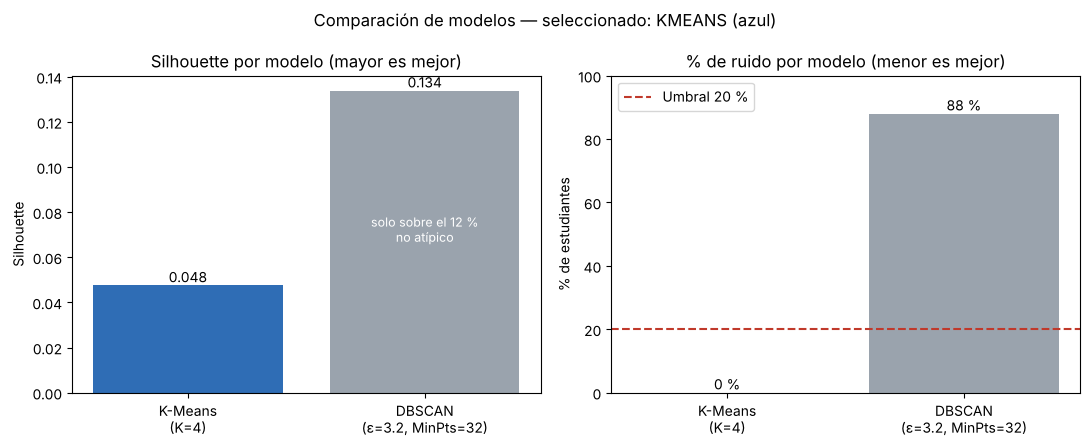

In [7]:
etiquetas = ["K-Means\n(K=4)", f"DBSCAN\n(ε={EPS}, MinPts={MIN_SAMPLES})"]
colores = ["#2f6db5" if s == "si" else "#9aa3ad" for s in comparacion["seleccionado"]]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

barras = axes[0].bar(etiquetas, comparacion["silhouette"], color=colores)
axes[0].bar_label(barras, fmt="%.3f")
axes[0].set_title("Silhouette por modelo (mayor es mejor)")
axes[0].set_ylabel("Silhouette")
axes[0].text(1, comparacion.loc[1, "silhouette"] / 2, "solo sobre el 12 %\nno atípico",
             ha="center", color="white", fontsize=9)

ruido_pct = comparacion["noise_pct"] * 100
barras = axes[1].bar(etiquetas, ruido_pct, color=colores)
axes[1].bar_label(barras, fmt="%.0f %%")
axes[1].axhline(UMBRAL_RUIDO * 100, color="#c0392b", linestyle="--", label="Umbral 20 %")
axes[1].set_title("% de ruido por modelo (menor es mejor)")
axes[1].set_ylabel("% de estudiantes")
axes[1].set_ylim(0, 100)
axes[1].legend(loc="upper left")

fig.suptitle(f"Comparación de modelos — seleccionado: {modelo_final.upper()} (azul)")
fig.tight_layout()
Path("figs").mkdir(exist_ok=True)
fig.savefig("figs/comparacion.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretación y Argumento para Defensa:**
1. *¿Qué significa?* A la izquierda DBSCAN parece ganar; a la derecha se ve el costo: su barra de ruido supera de lejos la línea del 20 %.
2. *Decisión:* los dos paneles juntos justifican elegir K-Means; ninguno de los dos basta por separado.
3. *Defensa:* "Una métrica de calidad que ignora a la mayoría de los datos no puede decidir sola; por eso comparamos calidad (Silhouette) y cobertura (ruido) lado a lado."

## 7. Interpretación de segmentos (modelo final: K-Means)

**Propósito y fundamento:** un cluster sin nombre no le sirve a la institución. Se promedian las variables **en su escala original** con `groupby().mean()` para leer cada perfil en unidades reales (horas, puntos, % de asistencia). Las proporciones de `Part_Time_Job` y `Counseling_Access` se calculan sobre los registros con dato. Los nombres vienen de `segments/segments_kmeans.json` (Paquete A); aquí se contrastan con los promedios y se les asigna una recomendación.

In [8]:
SEGMENTOS = json.loads(Path("segments/segments_kmeans.json").read_text(encoding="utf-8"))
RECOMENDACION = {
    "Rezago y presión financiera":
        "Becas o ayuda económica, tutorías para materias pendientes y plan de recuperación académica.",
    "Participación y apoyo familiar":
        "Mantener el acompañamiento; invitarlos como mentores pares de otros grupos.",
    "Baja asistencia y alta pantalla":
        "Alertas tempranas de asistencia y talleres sobre uso de pantallas y hábitos de sueño.",
    "Buen GPA con seguimiento de bienestar":
        "Reconocimiento académico y ofrecer consejería: alto estrés financiero y menor acceso a apoyo.",
}
assert set(SEGMENTOS.values()) == set(RECOMENDACION), "Cada segmento debe tener recomendación"

datos = df.assign(cluster=km_labels)
perfil = datos.groupby("cluster")[FEATURES].mean()
perfil.insert(0, "n", datos.groupby("cluster").size())
for col, nueva in [("Part_Time_Job", "prop_part_time_job"), ("Counseling_Access", "prop_counseling_access")]:
    perfil[nueva] = datos.groupby("cluster")[col].apply(lambda s: (s == "Yes").sum() / s.notna().sum())

# Debe coincidir con segments/perfiles_kmeans.csv del Paquete A.
guardado = pd.read_csv("segments/perfiles_kmeans.csv").set_index("cluster")
assert np.allclose(perfil[guardado.columns].to_numpy(dtype=float), guardado.to_numpy(dtype=float))

clave = ["n", "Previous_GPA", "Backlogs", "Attendance_Percent", "Screen_Time_Hours",
         "Financial_Stress_Score", "Stress_Level", "Family_Support_Score",
         "Motivation_Score", "prop_counseling_access"]
tabla = perfil[clave].round(2)
tabla.insert(0, "segmento", [SEGMENTOS[str(k)] for k in tabla.index])
display(tabla)

for k in perfil.index:
    nombre = SEGMENTOS[str(k)]
    print(f"Cluster {k} — {nombre} ({perfil.loc[k, 'n']} estudiantes): {RECOMENDACION[nombre]}")

,segmento,n,Previous_GPA,Backlogs,Attendance_Percent,Screen_Time_Hours,Financial_Stress_Score,Stress_Level,Family_Support_Score,Motivation_Score,prop_counseling_access
cluster,,,,,,,,,,,
0,Rezago y presión financiera,171,6.64,1.79,85.31,4.13,5.65,6.09,5.91,4.45,0.34
1,Participación y apoyo familiar,220,6.54,0.52,84.64,5.10,4.42,4.97,7.33,6.06,0.31
2,Baja asistencia y alta pantalla,206,6.60,0.73,69.09,6.72,4.27,5.31,5.18,5.38,0.37
3,Buen GPA con seguimiento de bienestar,203,7.64,0.44,69.21,5.56,5.93,5.87,7.14,5.80,0.31


Cluster 0 — Rezago y presión financiera (171 estudiantes): Becas o ayuda económica, tutorías para materias pendientes y plan de recuperación académica.
Cluster 1 — Participación y apoyo familiar (220 estudiantes): Mantener el acompañamiento; invitarlos como mentores pares de otros grupos.
Cluster 2 — Baja asistencia y alta pantalla (206 estudiantes): Alertas tempranas de asistencia y talleres sobre uso de pantallas y hábitos de sueño.
Cluster 3 — Buen GPA con seguimiento de bienestar (203 estudiantes): Reconocimiento académico y ofrecer consejería: alto estrés financiero y menor acceso a apoyo.


**Interpretación y Argumento para Defensa:**
- **Cluster 0 — Rezago y presión financiera (171):** el mayor número de materias pendientes (`Backlogs` 1.79, frente a 0.44–0.73 en los demás) y el mayor `Stress_Level` (6.09), con estrés financiero alto (5.65). → **Ayuda económica y tutorías.**
- **Cluster 1 — Participación y apoyo familiar (220):** el mayor apoyo familiar (7.33), la mayor motivación (6.06) y la mayor actividad social (5.98), con pocas materias pendientes (0.52). → **Mantener y usar como mentores.**
- **Cluster 2 — Baja asistencia y alta pantalla (206):** el mayor tiempo de pantalla (6.72 h) y asistencia baja (69.1 %, casi igual que el cluster 3, 69.2 %), con el menor apoyo familiar (5.18). → **Alertas de asistencia y hábitos.**
- **Cluster 3 — Buen GPA con seguimiento de bienestar (203):** el mejor GPA (7.64, un punto sobre el cluster 0), pero el mayor estrés financiero (5.93) y el menor acceso a consejería (30.5 %). → **Reconocimiento y consejería preventiva.**

1. *¿Qué significa para el negocio?* Cada perfil tiene una acción distinta, que es lo que exige el criterio de utilidad.
2. *¿Qué decisión técnica se toma?* Se conservan los nombres del Paquete A. Las diferencias entre grupos son de 0.5 a 2 puntos en escalas de 1 a 10, coherentes con un Silhouette bajo: son **tendencias**, no categorías tajantes.
3. *¿Cómo defenderlo? — "¿Cómo pusieron los nombres?"* Con los promedios en escala original de `groupby().mean()`: cada nombre se apoya en las variables donde el grupo es el más alto o el más bajo de los cuatro.

## 8. Exportación, verificación y prueba de inferencia

**Propósito y fundamento:** un modelo sólo sirve si la aplicación puede usarlo con datos crudos. Se verifica que (1) existen todos los artefactos del contrato que usan la app y el informe; (2) el pipeline de K-Means asigna un segmento a un registro con las 16 variables **sin escalar**, sin entrenar nada; y (3) el paquete DBSCAN, con el algoritmo `asignar_cluster_dbscan` del documento maestro, devuelve −1 cuando un registro no alcanza densidad.

In [9]:
REQUERIDOS = [
    "models/imputer.joblib", "models/scaler.joblib", "models/pca.joblib",
    "models/pipeline_kmeans.joblib", "models/pipeline_dbscan.joblib",
    "data/pca_2d.csv", "data/pca_varianza.csv",
    "segments/perfiles_kmeans.csv", "segments/labels_kmeans.csv", "segments/segments_kmeans.json",
    "segments/perfiles_dbscan.csv", "segments/labels_dbscan.csv", "segments/segments_dbscan.json",
    "tables/metrics_kmeans.csv", "tables/metrics_dbscan.csv", "tables/comparacion.csv",
    "figs/codo_kmeans.png", "figs/silhouette_kmeans.png", "figs/pca_kmeans.png",
    "figs/kdist_dbscan.png", "figs/pca_dbscan.png", "figs/comparacion.png",
]
faltan = [r for r in REQUERIDOS if not Path(r).exists()]
assert not faltan, f"Faltan artefactos: {faltan}"
print(f"Artefactos del contrato verificados: {len(REQUERIDOS)} de {len(REQUERIDOS)}")

# Inferencia con el pipeline exportado (el mismo que carga la app).
pipeline_final = joblib.load("models/pipeline_kmeans.joblib")
muestra = X_raw.iloc[[0, 1, 2]]          # tres registros reales, en escala original
pred = pipeline_final.predict(muestra)
assert np.array_equal(pred, km_labels[:3])
for i, k in zip(muestra.index, pred):
    print(f"Registro {i}: cluster {k} — {SEGMENTOS[str(k)]}")

# Inferencia DBSCAN para registros nuevos (algoritmo del documento maestro).
paquete_db = joblib.load("models/pipeline_dbscan.joblib")

def asignar_cluster_dbscan(X_new_raw, paquete):
    pasos = paquete["pipeline"].named_steps
    X_new = pasos["scaler"].transform(pasos["imputer"].transform(X_new_raw))
    dist, idx = paquete["nn_model"].kneighbors(X_new)
    return [int(paquete["core_labels"][i[0]]) if d[0] <= paquete["eps"] else -1
            for d, i in zip(dist, idx)]

print("\nDBSCAN sobre los mismos tres registros:", asignar_cluster_dbscan(muestra, paquete_db))

Artefactos del contrato verificados: 22 de 22
Registro 0: cluster 1 — Participación y apoyo familiar
Registro 1: cluster 2 — Baja asistencia y alta pantalla
Registro 2: cluster 3 — Buen GPA con seguimiento de bienestar

DBSCAN sobre los mismos tres registros: [-1, -1, 1]


**Interpretación y Argumento para Defensa:**
1. *¿Qué significa?* Todos los artefactos existen y el pipeline exportado predice lo mismo que el modelo reproducido. La app puede recibir datos crudos del formulario y llamar a `predict` sin escalar a mano.
2. *¿Qué decisión técnica se toma?* La app usa `models/pipeline_kmeans.joblib` para asignar el segmento, y `models/pca.joblib` **sólo** para dibujar el nuevo estudiante en el mapa 2D. Con DBSCAN, los mismos registros caen como −1 o en un grupo según su distancia al core más cercano, lo que confirma en la práctica el problema de cobertura.
3. *¿Cómo defenderlo? — "¿Por qué DBSCAN necesita NearestNeighbors y K-Means no?"* `KMeans` tiene `predict`: asigna el centroide más cercano. `DBSCAN` de scikit-learn no tiene `predict`; para un registro nuevo se busca el punto core más cercano y, si está a distancia ≤ ε, se hereda su etiqueta; si no, es ruido.

## 9. Resumen para la sustentación (todo el equipo)

| Pregunta típica | Respuesta corta |
| :--- | :--- |
| ¿Por qué es clustering y no clasificación? | No usamos `Burnout_Level` ni `Dropout_Risk`; los grupos salen sólo de la distancia entre estudiantes en 16 variables. |
| ¿Por qué escalar? | Ambos algoritmos usan distancia euclidiana; sin escalar, las variables con números grandes dominarían. |
| ¿Por qué K=4? | Codo de la inercia en K=4; Silhouette bajo y casi plano entre K=2 y K=9, así que se prefirió el número de perfiles más manejable. |
| ¿Por qué DBSCAN dejó 88 % de ruido? | En 16D casi ningún estudiante tiene 32 vecinos a menos de 3.2; es la maldición de la dimensionalidad. |
| ¿Por qué ganó K-Means? | Cobertura de 100 % frente a 12 %, y DBSCAN supera el umbral de ruido de 20 % fijado de antemano. |
| ¿Cuál es la principal limitación? | Silhouette de 0.047: los grupos se solapan. Son tendencias para priorizar apoyo, no diagnósticos individuales. |
| ¿Qué muestra el mapa 2D? | Sólo el 15 % de la varianza (PC1 + PC2); sirve para ubicar al estudiante, no para decidir su grupo. |